# O grappling vence lutas ou convence juízes?
## Reanálise dos indicadores de desempenho no UFC estratificada por método de vitória

**Disciplina:** SME0828 - Introdução à Ciência de Dados
**Instituição:** ICMC-USP
**Docente:** Prof. Francisco A. Rodrigues
**Grupo:**
- Pedro Henrique de Sousa Prestes (15507819)
- Laura Pazini Medeiros (15468452)
- `<Nome>` (`<nº USP>`)

**Dados:** [UFC Stats](http://ufcstats.com), coleta de **2026-09-21** (`data/ufc-stats-2026-09-21/`).

---

> **Hipótese.** *A vantagem aparente do grappling se dissolve quando a amostra é restrita a lutas que foram à decisão.*

### Resumo

`<Preencher ao final: pergunta, dados (n lutas por estrato), método principal (logística com interação estrato × indicador, SE agrupado por lutador), resultado (a hipótese foi confirmada ou refutada, com tamanho de efeito) e principal limitação (viés de seleção ao condicionar na decisão).>`

### Roteiro do notebook

| # | Seção | Passo do enunciado |
|---|---|---|
| 1 | Introdução: o problema, a hipótese e o que já se sabe | Pergunta e hipótese |
| 2 | Obtenção dos dados | Coleta |
| 3 | Preparação e limpeza dos dados | 1 |
| 4 | Unidade de análise e engenharia de atributos | 1, 7 |
| 5 | Estatística descritiva | 2 |
| 6 | Análise exploratória: há algum padrão? | 3 |
| 7 | Que tipo de problema é este? | 4 |
| 8 | Teste formal da hipótese (inferência) | 5, 8 |
| 9 | Modelos supervisionados: ajuste e seleção | 5 |
| 10 | Comparação dos modelos | 6 |
| 11 | É possível melhorar? Projeção, seleção e transformação | 7 |
| 12 | Resultados finais e importância das variáveis | 8 |
| 13 | Análises de sensibilidade | 8 |
| 14 | Análise exploratória secundária: o placar dos juízes | 8 |
| 15 | Discussão | 9 |
| 16 | Conclusão e sumário do projeto | 10 |

In [1]:
# !pip install -r requirements.txt -q

In [2]:
from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf

from sklearn.model_selection import (train_test_split, StratifiedKFold, RepeatedStratifiedKFold,
                                     GridSearchCV, RandomizedSearchCV, cross_validate)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, QuantileTransformer
from sklearn.decomposition import PCA
from sklearn.feature_selection import RFECV
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.calibration import CalibrationDisplay
from sklearn.metrics import (roc_auc_score, accuracy_score, f1_score, brier_score_loss, log_loss,
                             RocCurveDisplay, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 60)

SEED = 42
DATA_DIR = Path("data/ufc-stats-2026-09-21")
FIG_DIR = Path("figures")
RESULTS_DIR = Path("results")
FIG_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)

# Janela posterior à amostra de James et al. (2014); ver docs/DESENHO.md.
INICIO_JANELA = "2015-01-01"

In [3]:
# Paleta validada para daltonismo (3 estratos = 3 primeiras cores, válidas em todos os pares).
ESTRATOS = ["KO/TKO", "Finalização", "Decisão"]
COR_ESTRATO = {"KO/TKO": "#2a78d6", "Finalização": "#eb6834", "Decisão": "#1baf7a"}
COR_TEXTO, COR_TEXTO_2, COR_GRADE, COR_FUNDO = "#0b0b0b", "#52514e", "#e1e0d9", "#fcfcfb"
DIVERGENTE = sns.blend_palette(["#2a78d6", "#f0efec", "#e34948"], as_cmap=True)

plt.rcParams.update({
    "figure.facecolor": COR_FUNDO, "axes.facecolor": COR_FUNDO, "savefig.facecolor": COR_FUNDO,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": COR_TEXTO_2, "text.color": COR_TEXTO,
    "xtick.color": COR_TEXTO_2, "ytick.color": COR_TEXTO_2,
    "axes.grid": True, "grid.color": COR_GRADE, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "lines.linewidth": 2, "font.size": 11, "axes.titlesize": 13, "axes.titleweight": "bold",
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
})


def salvar(fig, nome):
    fig.savefig(FIG_DIR / f"{nome}.png")

# 1. Introdução

## 1.1 O MMA em poucas palavras

O **UFC** (*Ultimate Fighting Championship*) é a maior organização de **MMA** (*Mixed Martial Arts*, artes marciais mistas). No MMA, dois lutadores se enfrentam em um octógono cercado por uma grade e podem usar praticamente qualquer arte marcial: boxe, chutes, luta olímpica, jiu-jitsu.

**Como é uma luta.** São **3 rounds de 5 minutos** (ou 5 rounds nas lutas principais e de título). A luta pode acabar de três formas:

| Forma de terminar | O que acontece | Estrato nesta análise |
|---|---|---|
| **Nocaute (KO) ou nocaute técnico (TKO)** | Um lutador é derrubado inconsciente pelos golpes (KO), ou o árbitro interrompe porque ele não consegue mais se defender (TKO) | KO/TKO |
| **Finalização** (*submission*) | Um lutador aplica uma chave de braço, perna ou um estrangulamento, e o adversário desiste ("bate") ou desmaia | Finalização |
| **Decisão dos juízes** | Ninguém terminou a luta no tempo; três juízes dão notas a cada round e quem somar mais pontos vence | Decisão |

**Os dois "jeitos" de lutar.** As habilidades se dividem em dois grandes grupos:

- **Striking (trocação):** lutar **em pé**, golpeando com socos, chutes, joelhadas e cotoveladas. Vem do boxe, muay thai e kickboxing.
- **Grappling (luta agarrada):** **agarrar, derrubar e dominar** o adversário, quase sempre no chão. Vem da luta olímpica (*wrestling*) e do jiu-jitsu.

Termos do grappling usados neste trabalho:

| Termo | Significado | Variável |
|---|---|---|
| **Queda** (*takedown*) | Levar o adversário do pé para o chão | `td_landed`, `td_attempted` |
| **Tempo de controle** | Tempo em que um lutador mantém o outro dominado (por cima no chão ou preso contra a grade) | `ctrl_seconds` |
| **Golpes no solo** | Golpes dados com os dois lutadores no chão | `ground_landed` |
| ***Ground and pound*** | Derrubar o adversário, ficar por cima e golpeá-lo de cima para baixo. É o caminho mais comum de um especialista em grappling para vencer por TKO | `ground_landed` em lutas que terminam em KO/TKO |
| **Tentativa de finalização** | Tentar uma chave ou estrangulamento | `sub_att` |

O site **UFC Stats** registra, para cada lutador em cada luta, quantas vezes cada uma dessas ações aconteceu. Isso é o que chamamos de **análise notacional**: descrever uma luta por contagens de ações, como as estatísticas de passes e finalizações de uma partida de futebol.

## 1.2 O estudo de partida: "o grappling decide lutas"

James et al. (2016, *Journal of Science and Medicine in Sport*) analisaram 234 lutas do UFC de 2014 com **árvores de decisão**: um algoritmo que separa os lutadores em grupos por perguntas simples do tipo "acertou mais que X golpes?" e mostra quantos venceram em cada grupo.

Duas regras encontradas:

| Regra | Leitura |
|---|---|
| Mais de 0,850 golpes no solo por minuto → **91,5%** venceram | Quem acertou cerca de 4 ou mais golpes no chão a cada round de 5 minutos quase sempre ganhou |
| Mais de 4 golpes no solo **e** precisão de quedas acima de 25% → **84,9%** venceram | Quem golpeou no chão e acertou mais de 1 a cada 4 tentativas de queda ganhou na grande maioria das vezes |

Os indicadores mais importantes foram de **grappling**. A conclusão dos autores: *dominar o adversário no chão e golpeá-lo é o que mais distingue vencedores de perdedores*. Isso orienta, por exemplo, como treinadores priorizam o treino.

## 1.3 O problema: o indicador pode ser o próprio resultado

As estatísticas são contadas **durante a própria luta**, e o estudo juntou todas as formas de vitória num só modelo. Isso cria uma armadilha.

Pense numa luta que termina por *ground and pound*: o lutador derruba o adversário, fica por cima e acerta 15 golpes até o árbitro parar a luta. Os 15 golpes no solo **não anteciparam** a vitória: **eles foram a vitória**. Dizer "quem golpeia muito no chão vence" vira algo parecido com "no futebol, quem faz mais gols vence": verdadeiro, mas sem explicar nada.

Duas coisas agravam o efeito:

- **Lutas curtas inflam as taxas.** Um nocaute no chão em 1 minuto com 10 golpes vira "10 golpes por minuto", muito acima do limiar de 0,850. Os nocautes rápidos empurram a regra para cima.
- **Finalizações têm o mesmo problema.** Quem venceu por finalização obrigatoriamente tentou finalizar.

## 1.4 A ideia deste trabalho: olhar só as lutas que ninguém terminou

Nas lutas que vão à **decisão dos juízes**, ninguém foi nocauteado nem finalizado. O resultado não é a consequência mecânica dos golpes contados: é o **julgamento de três pessoas** sobre quem foi melhor nos 15 (ou 25) minutos.

Se o grappling realmente distingue vencedores de perdedores, ele deve continuar importante também nessas lutas. Se a importância dele vinha da forma como as lutas terminam (*ground and pound*, finalizações), ela deve **diminuir ou sumir** quando olhamos só as decisões.

Para fazer essa comparação, dividimos as lutas em **estratos**. Um estrato é um **subgrupo da amostra formado por um critério fixo**; aqui o critério é **a forma como a luta terminou**, o que dá três estratos: **KO/TKO**, **Finalização** e **Decisão** (última coluna da tabela da Seção 1.1). Cada estrato é analisado em separado e depois comparado com os outros. Juntar tudo em um único modelo, como fizeram James et al., pode esconder que a relação muda de um grupo para outro, do mesmo jeito que avaliar um remédio misturando pacientes leves e graves pode dar uma média enganosa.

Por isso a hipótese do trabalho é:

> **A vantagem aparente do grappling se dissolve quando a amostra é restrita a lutas que foram à decisão.**

**Os dois resultados possíveis são informativos:**

- **O efeito do grappling encolhe nas decisões:** o achado de James et al. estava inflado pela mecânica de como as lutas terminam.
- **O efeito persiste ou aumenta:** o grappling continua separando vencedores, mas agora a afirmação é sobre **o que os juízes premiam**, não sobre o que termina lutas.

## 1.5 O que já se sabe e onde está a lacuna

| Trabalho | O que fez | Limite em relação a esta pergunta |
|---|---|---|
| James et al. (2016, *JSAMS*) | Classificação de vitória, todas as formas de vitória juntas | Não separa por forma de vitória; duas linhas espelhadas por luta |
| James et al. (2019, *Front. AI*) | 2.831 lutas (2000–2015); a duração aparece em 3 de 8 regras | Ainda junta as formas de vitória |
| Miarka et al. (2016, 2018, *JSCR*) | Compara **frequências** de técnicas entre KO/TKO, finalização e decisão | Descritivo; não testa se o **modelo** muda entre as formas de vitória |
| Latshaw (JudgeAI); Gift (2021, *J. Sports Analytics*) | Modelam o vencedor de cada round pelos juízes | Outra pergunta: modelar os juízes |

**Contribuição deste trabalho:** testar formalmente (interação estrato × indicador) se os indicadores de vitória de James et al. são os mesmos nos três estratos, usando uma variável que eles não tinham: o **tempo de controle**.

## 1.6 Pergunta e hipóteses

**Pergunta principal.** A relação entre grappling e vitória é diferente nas lutas terminadas por nocaute ou finalização e nas lutas decididas pelos juízes?

| Hipótese | Enunciado | Como será testada |
|---|---|---|
| **H3** (principal) | A vantagem aparente do grappling se dissolve quando a amostra é restrita a lutas que foram à decisão | Seções 6.5, 8 e 10 |
| H3a | O efeito dos indicadores de grappling sobre a vitória é **menor** nas decisões do que nos nocautes e finalizações | Termos de interação estrato × indicador (Seção 8) |
| H3b | Nas decisões, o **tempo de controle** é o indicador de grappling mais ligado à vitória, à frente dos golpes no solo | Comparação de coeficientes e importâncias dentro do estrato (Seções 8 e 12) |
| H3c | Nas decisões, os **golpes à distância** (striking em pé) ganham a importância que perdem no modelo com todas as lutas | Importâncias e ΔAUC por bloco (Seções 10 e 12) |

> **Pergunta descritiva, não de causa e efeito.** As lutas que chegam à decisão não são uma amostra qualquer: são mais equilibradas, e o próprio grappling influencia se a luta chega lá. A pergunta correta é: *entre as lutas que chegam à decisão, o que distingue vencedores de perdedores?* Retomamos este ponto na Seção 15.

O desenho completo, as referências e as decisões metodológicas estão em [`docs/DESENHO.md`](docs/DESENHO.md).

# 2. Obtenção dos dados

Os dados vêm do [UFC Stats](http://ufcstats.com), base pública alimentada pela FightMetric. A coleta é um retrato do site em **2026-09-21**: recoletar depois dá números diferentes, então a análise fixa esta data.

> **Observação sobre a coleta.** Os dados foram coletados do UFC Stats por um *scraper* desenvolvido pelo próprio grupo: [`ufc-stats-scraper`](https://github.com/JuanHPassos/ufc-stats-scraper). O repositório está **privado no momento** e será tornado **público** depois. O scraper baixa o HTML bruto de todos os eventos, lutas e lutadores, guarda-o em cache para reprodutibilidade e gera as cinco tabelas relacionais abaixo. Ele não faz nenhuma análise.

| tabela | linhas | granularidade |
|---|---|---|
| `events` | 789 | um evento (1994–2026) |
| `fights` | 8.897 | uma luta |
| `fight_stats` | 17.752 | um lutador por luta (totais) |
| `round_stats` | 41.792 | um lutador por round |
| `fighters` | 4.618 | um lutador |

Todas as 13 checagens de integridade e consistência do scraper passaram (`data/ufc-stats-2026-09-21/relatorios/validation_report.md`). A descrição de cada coluna está em `DICIONARIO-DE-DADOS.md`.

**Todos os indicadores do desenho existem no UFC Stats**, exceto *offensive passes* (passagens de guarda), usado por James et al. a partir do feed completo da FightMetric. O tempo de controle entra como medida contínua do domínio posicional no solo.

In [4]:
events = pd.read_parquet(DATA_DIR / "events.parquet")
fights = pd.read_parquet(DATA_DIR / "fights.parquet")
fight_stats = pd.read_parquet(DATA_DIR / "fight_stats.parquet")
round_stats = pd.read_parquet(DATA_DIR / "round_stats.parquet")
fighters = pd.read_parquet(DATA_DIR / "fighters.parquet")

for nome, tabela in [("events", events), ("fights", fights), ("fight_stats", fight_stats),
                     ("round_stats", round_stats), ("fighters", fighters)]:
    print(f"{nome:12s} {tabela.shape[0]:>6,d} linhas x {tabela.shape[1]:>2d} colunas")

events          789 linhas x  6 colunas
fights        8,897 linhas x 28 colunas
fight_stats  17,752 linhas x 26 colunas
round_stats  41,792 linhas x 27 colunas
fighters      4,618 linhas x 22 colunas


In [5]:
fights.head(3)

,fight_id,event_id,card_position,fighter_a_id,fighter_b_id,fighter_order_source,winner_id,result_type,weight_class,weight_class_card,weight_class_raw,is_title_fight,is_women,bonuses,method,method_raw,method_detail,went_to_decision,end_round,end_time_seconds,total_fight_seconds,scheduled_rounds,time_format_raw,referee,judges_scores,details_raw,scraped_at,source_url
0,810c9da07970c4a6,00a905a4a4a2b071,1,787bb1f087ccff8a,c62fbc117d57b943,fight_page,787bb1f087ccff8a,win,Heavyweight,Heavyweight,Heavyweight Bout,False,False,"[""fight_of_the_night""]",KO/TKO,KO/TKO,Punches,False,3,263,863,5,5 Rnd (5-5-5-5-5),Marc Goddard,<NA>,Punches to Head At Distance,2026-09-21,http://ufcstats.com/fight-details/810c9da07970...
1,b8ca1acdf3dc2f58,00a905a4a4a2b071,2,e1147d3d2dabe1ce,7acbb0972e75281a,fight_page,e1147d3d2dabe1ce,win,Middleweight,Middleweight,Middleweight Bout,False,False,[],U-DEC,U-DEC,<NA>,True,3,300,900,3,3 Rnd (5-5-5),Jason Herzog,"[{""judge"": ""Mark Collett"", ""score_1"": 27, ""sco...",Mark Collett 27 - 30. Howard Hughes 27 - 30. C...,2026-09-21,http://ufcstats.com/fight-details/b8ca1acdf3dc...
2,20f316f96c9e4458,00a905a4a4a2b071,3,881bf86d4cba8578,b9437600497350f3,fight_page,881bf86d4cba8578,win,Middleweight,Middleweight,Middleweight Bout,False,False,[],U-DEC,U-DEC,<NA>,True,3,300,900,3,3 Rnd (5-5-5),Marc Goddard,"[{""judge"": ""Ben Cartlidge"", ""score_1"": 28, ""sc...",Ben Cartlidge 28 - 29. Mark Collett 28 - 29. D...,2026-09-21,http://ufcstats.com/fight-details/20f316f96c9e...


In [6]:
fight_stats.head(3)

,fight_id,fighter_id,kd,sig_str_landed,sig_str_attempted,total_str_landed,total_str_attempted,td_landed,td_attempted,sub_att,rev,ctrl_seconds,head_landed,head_attempted,body_landed,body_attempted,leg_landed,leg_attempted,distance_landed,distance_attempted,clinch_landed,clinch_attempted,ground_landed,ground_attempted,scraped_at,source_url
0,0005e00b07cee542,634e2fb70bde3fd5,0,154,301,187,342,5,14,0,0,316,81,214,56,68,17,19,140,272,1,1,13,28,2026-09-21,http://ufcstats.com/fight-details/0005e00b07ce...
1,0005e00b07cee542,578ef12674df1e6a,0,69,185,92,210,0,0,0,0,3,38,128,12,30,19,27,65,181,4,4,0,0,2026-09-21,http://ufcstats.com/fight-details/0005e00b07ce...
2,000da3152b7b5ab1,6da99156486ed6c2,1,35,88,60,113,4,7,0,0,404,22,72,9,12,4,4,14,50,16,28,5,10,2026-09-21,http://ufcstats.com/fight-details/000da3152b7b...


# 3. Preparação e limpeza dos dados

Antes de qualquer análise, mapeamos os desafios listados no enunciado para esta base:

| Desafio | Onde aparece aqui | Tratamento |
|---|---|---|
| Dados não independentes | Duas linhas por luta (vencedor e perdedor, espelhadas); o mesmo lutador em várias lutas | Uma linha por luta (Seção 4); erros-padrão agrupados por lutador (Seção 8) |
| Desbalanceamento | Estratos de tamanhos diferentes (finalizações ≈ 1/3 das decisões); se o vencedor fosse sempre a referência, y seria constante | Sorteio do lutador de referência (y ≈ 50%); métricas por estrato |
| Dados incompletos | Lutas antigas sem estatísticas; `ctrl_seconds` nulo em eras intermediárias | Recorte temporal; teste de ausência aleatória |
| Outliers | Taxas por minuto explodem em lutas muito curtas | Critério de duração mínima; transformações (Seção 11) |
| Variáveis irrelevantes / vazamento | Cartel e médias de carreira em `fighters` incluem lutas futuras; ordem A/B pré-2010 = vencedor primeiro | Excluídos; sorteio da referência |
| Excesso de atributos | Contagens redundantes (golpes totais × significativos × por posição) | Blocos de atributos; correlação e VIF (Seção 6.4) |
| Poucas observações | Estrato de finalizações (~1.000 lutas) | Árvores com mínimo de casos por folha; intervalos por bootstrap |

## 3.1 Tipos, duplicatas e consistência

O Parquet já traz os tipos corretos: inteiros que aceitam nulo (`Int64`), datas e booleanos. Conferimos as chaves primárias e as relações lógicas entre as contagens (o acertado não pode passar do tentado, os golpes por posição somam os significativos etc.).

In [7]:
def sem_violacao(condicao):
    # Comparações com nulo viram <NA>; nulo não é violação.
    return bool(condicao.fillna(True).all())


fs = fight_stats
checagens = {
    "events.event_id único": events.event_id.is_unique,
    "fights.fight_id único": fights.fight_id.is_unique,
    "fighters.fighter_id único": fighters.fighter_id.is_unique,
    "fight_stats (fight_id, fighter_id) único": not fs.duplicated(["fight_id", "fighter_id"]).any(),
    "round_stats (fight_id, fighter_id, round) único": not round_stats.duplicated(["fight_id", "fighter_id", "round"]).any(),
    "nenhuma linha totalmente duplicada": not fs.drop(columns=["scraped_at"]).duplicated().any(),
    "todo fight_stats aponta para uma luta": fs.fight_id.isin(fights.fight_id).all(),
}
for prefixo in ["sig_str", "total_str", "td", "head", "body", "leg", "distance", "clinch", "ground"]:
    checagens[f"{prefixo}_landed <= {prefixo}_attempted"] = sem_violacao(fs[f"{prefixo}_landed"] <= fs[f"{prefixo}_attempted"])
checagens["sig_str_landed <= total_str_landed"] = sem_violacao(fs.sig_str_landed <= fs.total_str_landed)
checagens["distância + clinch + solo = significativos"] = sem_violacao(
    fs.distance_landed + fs.clinch_landed + fs.ground_landed == fs.sig_str_landed)
duracao = fs.fight_id.map(fights.set_index("fight_id").total_fight_seconds)
checagens["ctrl_seconds <= duração da luta"] = sem_violacao(fs.ctrl_seconds <= duracao)

pd.Series(checagens, name="ok").to_frame()

,ok
events.event_id único,True
fights.fight_id único,True
fighters.fighter_id único,True
"fight_stats (fight_id, fighter_id) único",True
"round_stats (fight_id, fighter_id, round) único",True
nenhuma linha totalmente duplicada,True
todo fight_stats aponta para uma luta,True
sig_str_landed <= sig_str_attempted,True
total_str_landed <= total_str_attempted,True
td_landed <= td_attempted,True


**Resultado.** As 19 checagens passaram: chaves únicas, nenhuma linha duplicada e nenhuma contagem inconsistente. Isso confirma o `validation_report` do scraper; não há correção a fazer nesta etapa.

## 3.2 Recorte temporal

Segundo o `coverage_report.md`, o tempo de controle é confiável desde **2000** e a ordem A/B reflete os cantos só desde **2010**. Usamos lutas a partir de **2015-01-01**:

- é posterior à amostra de James et al. (2014), então não há sobreposição;
- a cobertura de `ctrl_seconds` é praticamente completa;
- inclui a revisão dos critérios de julgamento de 2017, usada como análise de sensibilidade (Seção 13).

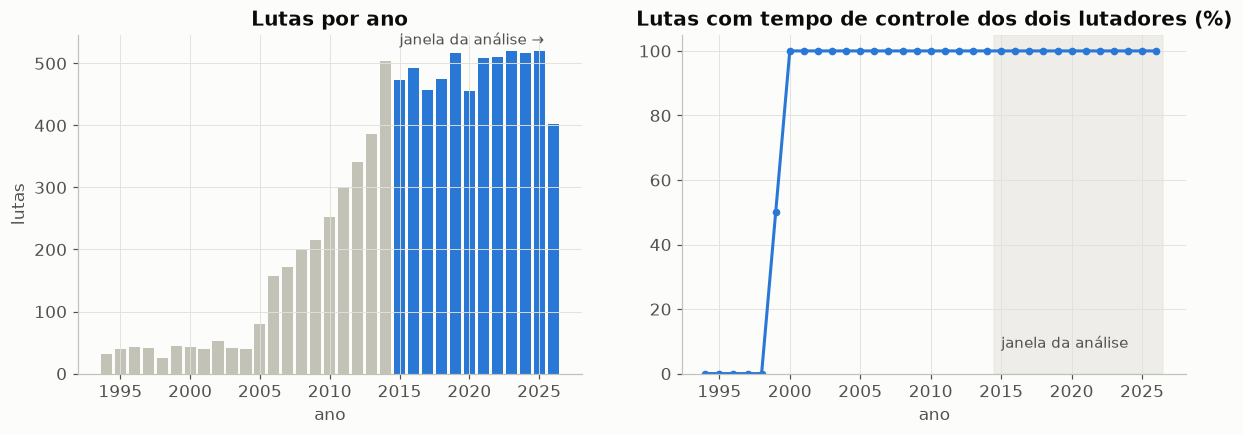

Lutas na janela: 5,849 (2015-01-03 a 2026-09-19)


In [8]:
fights = fights.merge(events[["event_id", "date"]], on="event_id", how="left")
fights["date"] = pd.to_datetime(fights["date"])
fights["ano"] = fights["date"].dt.year

ctrl_completo = fight_stats.ctrl_seconds.notna().groupby(fight_stats.fight_id).all()
por_ano = (fights.assign(tem_ctrl=fights.fight_id.map(ctrl_completo).fillna(False).astype(bool))
                 .groupby("ano").agg(lutas=("fight_id", "size"), pct_ctrl=("tem_ctrl", "mean")))
por_ano["pct_ctrl"] *= 100
ano_inicio = pd.Timestamp(INICIO_JANELA).year
na_janela = por_ano.index >= ano_inicio

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
ax1.bar(por_ano.index, por_ano.lutas, width=0.8,
        color=np.where(na_janela, COR_ESTRATO["KO/TKO"], "#c3c2b7"))
ax1.set_title("Lutas por ano")
ax1.set_ylabel("lutas")
ax1.text(ano_inicio, por_ano.lutas.max() * 1.02, "janela da análise →", color=COR_TEXTO_2, fontsize=10)
ax2.plot(por_ano.index, por_ano.pct_ctrl, color=COR_ESTRATO["KO/TKO"], marker="o", markersize=4)
ax2.axvspan(ano_inicio - 0.5, por_ano.index.max() + 0.5, color=COR_GRADE, alpha=0.5, zorder=0)
ax2.set_title("Lutas com tempo de controle dos dois lutadores (%)")
ax2.set_ylim(0, 105)
ax2.text(ano_inicio, 8, "janela da análise", color=COR_TEXTO_2, fontsize=10)
for ax in (ax1, ax2):
    ax.set_xlabel("ano")
salvar(fig, "fig01_lutas_por_ano_cobertura_ctrl")
plt.show()

janela = fights[fights["date"] >= INICIO_JANELA].copy()
print(f"Lutas na janela: {len(janela):,} ({janela.date.min():%Y-%m-%d} a {janela.date.max():%Y-%m-%d})")

**Resultado.** A janela tem **5.849 lutas** (3/1/2015 a 19/9/2026), entre 450 e 520 por ano (2026 vai só até setembro). O tempo de controle está registrado para os dois lutadores em **100% das lutas desde 2000**, então o início em 2015 não é imposto pela cobertura dos dados: vem da comparação com James et al. A janela de 2000 em diante fica como análise de sensibilidade (Seção 13).

## 3.3 Critérios de exclusão e definição dos estratos

| `method` | Estrato | Decisão |
|---|---|---|
| `KO/TKO` | KO/TKO | mantém |
| `SUB` | Finalização | mantém |
| `U-DEC`, `S-DEC`, `M-DEC` | Decisão | mantém (**estrato focal**) |
| `DQ`, `OVERTURNED`, `CNC`, `OTHER` | — | exclui (sem vencedor legítimo ou desfecho atípico) |
| `result_type` ∈ {`draw`, `no_contest`} | — | exclui (sem vencedor) |

`DQ` é desqualificação, `OVERTURNED` é resultado anulado depois (em geral por doping) e `CNC` é luta que não pôde continuar (*could not continue*, por exemplo após golpe ilegal acidental).

In [9]:
MAPA_ESTRATO = {"KO/TKO": "KO/TKO", "SUB": "Finalização",
                "U-DEC": "Decisão", "S-DEC": "Decisão", "M-DEC": "Decisão"}

display(pd.crosstab(janela.method, janela.result_type, margins=True, margins_name="total"))

funil = [("Lutas na janela (2015+)", janela)]
lutas = janela[janela.result_type.eq("win") & janela.method.isin(list(MAPA_ESTRATO))].copy()
lutas["estrato"] = pd.Categorical(lutas.method.map(MAPA_ESTRATO), categories=ESTRATOS)
funil.append(("Com vencedor e método válido", lutas))

lutas.estrato.value_counts().reindex(ESTRATOS).to_frame("lutas")

result_type,draw,no_contest,win,total
method,,,,
CNC,0,25,0,25
DQ,0,0,13,13
KO/TKO,0,0,1865,1865
M-DEC,30,0,44,74
OVERTURNED,1,34,0,35
S-DEC,13,0,566,579
SUB,0,0,1028,1028
U-DEC,3,0,2227,2230
total,47,59,5743,5849


,lutas
estrato,
KO/TKO,1865
Finalização,1028
Decisão,2837


**Resultado.** Saem 119 lutas (2%): 47 empates, 59 *no contests* e 13 desqualificações. Restam 5.730 lutas: **2.837 decisões** (49,5%), **1.865 KO/TKO** (32,5%) e **1.028 finalizações** (17,9%). As decisões divididas (`S-DEC`, 566) e majoritárias (`M-DEC`, 44) ficam no estrato Decisão; a diferença entre elas volta na Seção 14.

## 3.4 Vazamento de dados: ordem A/B e atributos de carreira

- **Ordem A/B.** Até 2009 o site lista o vencedor primeiro (`winner_id == fighter_a_id` em 100% das lutas). Depois de 2010 a taxa cai, mas não chega a 50% (vantagem do canto vermelho, que costuma ser do lutador favorito). Usar A/B como referência introduziria um viés; por isso a referência é **sorteada** (Seção 4).
- **Tabela `fighters`.** Cartel (`wins`, `losses`) e médias de carreira (`slpm`, `td_avg`…) são da data da coleta e incluem lutas posteriores a cada luta analisada. **Não são usados.**
- **Colunas de rastreio e texto bruto** (`scraped_at`, `source_url`, `*_raw`, `referee`, `bonuses`…) não entram na análise.

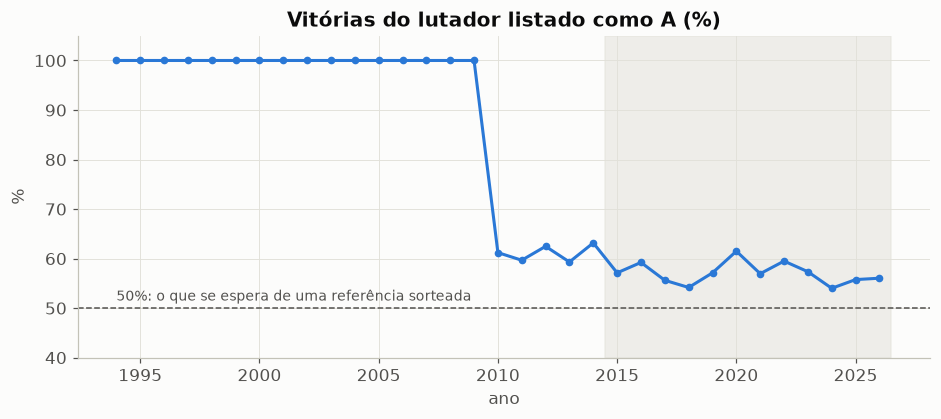

Na janela (2015+): o lutador A venceu 57.0% das lutas (média dos anos)


In [10]:
com_vencedor = fights[fights.result_type.eq("win")]
pct_a = (com_vencedor.winner_id == com_vencedor.fighter_a_id).groupby(com_vencedor.ano).mean() * 100

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(pct_a.index, pct_a.values, color=COR_ESTRATO["KO/TKO"], marker="o", markersize=4)
ax.axhline(50, color=COR_TEXTO_2, linewidth=1, linestyle="--")
ax.text(pct_a.index.min(), 51.5, "50%: o que se espera de uma referência sorteada", color=COR_TEXTO_2, fontsize=9)
ax.axvspan(ano_inicio - 0.5, pct_a.index.max() + 0.5, color=COR_GRADE, alpha=0.5, zorder=0)
ax.set_ylim(40, 105)
ax.set_title("Vitórias do lutador listado como A (%)")
ax.set_xlabel("ano")
ax.set_ylabel("%")
salvar(fig, "fig02_vitorias_lutador_a")
plt.show()

print(f"Na janela ({ano_inicio}+): o lutador A venceu {pct_a[pct_a.index >= ano_inicio].mean():.1f}% das lutas (média dos anos)")

COLUNAS_LUTA = ["fight_id", "event_id", "date", "ano", "fighter_a_id", "fighter_b_id", "winner_id",
                "method", "estrato", "weight_class", "is_women", "is_title_fight",
                "scheduled_rounds", "end_round", "total_fight_seconds", "judges_scores"]
lutas = lutas[COLUNAS_LUTA]

**Resultado.** Até 2009 o lutador A vence 100% das lutas, por construção do site. Na janela, ainda vence **57,0%** em média. Usar A como referência daria à resposta um viés de 7 pontos percentuais sem relação com o que aconteceu na luta. Na Seção 4 a referência é sorteada.

## 3.5 Valores ausentes: nulo não é zero

Lutas sem estatísticas não têm linha em `fight_stats`; zero significa que a ação aconteceu zero vezes. Uma luta só é utilizável se tiver **as linhas dos dois lutadores** e o **tempo de controle dos dois**, a variável central da H3b.

In [11]:
stats_janela = fight_stats[fight_stats.fight_id.isin(lutas.fight_id)]
linhas_por_luta = stats_janela.groupby("fight_id").size()
lutas["tem_stats"] = lutas.fight_id.map(linhas_por_luta).eq(2)
lutas["tem_ctrl"] = lutas.fight_id.map(stats_janela.ctrl_seconds.notna().groupby(stats_janela.fight_id).all())
lutas["tem_ctrl"] = lutas["tem_ctrl"].fillna(False).astype(bool)

nulos = stats_janela.isna().sum()
if nulos.any():
    display(nulos[nulos > 0].to_frame("nulos"))
else:
    print("Nenhuma coluna de fight_stats tem nulos na janela.")

ausencia = lutas.groupby("estrato", observed=True).agg(
    lutas=("fight_id", "size"),
    sem_stats=("tem_stats", lambda s: (~s).sum()),
    sem_ctrl=("tem_ctrl", lambda s: (~s).sum()),
)
ausencia["pct_sem_ctrl"] = (100 * ausencia.sem_ctrl / ausencia.lutas).round(2)
display(ausencia)

# chi2_contingency falha se uma das colunas da tabela é toda zero.
if (~lutas.tem_ctrl).sum() > 0:
    for fator in ["estrato", "ano"]:
        tabela = pd.crosstab(lutas[fator], lutas.tem_ctrl)
        chi2, p, gl, _ = stats.chi2_contingency(tabela)
        print(f"Ausência de ctrl x {fator}: chi2 = {chi2:.1f}, gl = {gl}, p = {p:.3g}")
else:
    print("Nenhuma luta sem tempo de controle: o teste de ausência aleatória não se aplica.")

lutas = lutas[lutas.tem_stats]
funil.append(("Com estatísticas dos dois lutadores", lutas))
lutas = lutas[lutas.tem_ctrl]
funil.append(("Com tempo de controle dos dois", lutas))

Nenhuma coluna de fight_stats tem nulos na janela.


,lutas,sem_stats,sem_ctrl,pct_sem_ctrl
estrato,,,,
KO/TKO,1865,0,0,0.0
Finalização,1028,0,0,0.0
Decisão,2837,0,0,0.0


Nenhuma luta sem tempo de controle: o teste de ausência aleatória não se aplica.


**Resultado.** Na janela, todas as lutas têm as linhas dos dois lutadores e nenhuma estatística é nula, inclusive o tempo de controle. Não há exclusão nem imputação a fazer, e o teste de ausência aleatória não se aplica.

## 3.6 Outliers e lutas muito curtas

Todas as variáveis são normalizadas pela duração (`total_fight_seconds`). Em lutas de poucos segundos as taxas por minuto explodem: um único golpe em 20 s vira 3 golpes/min. Esses casos estão quase todos no estrato KO/TKO.

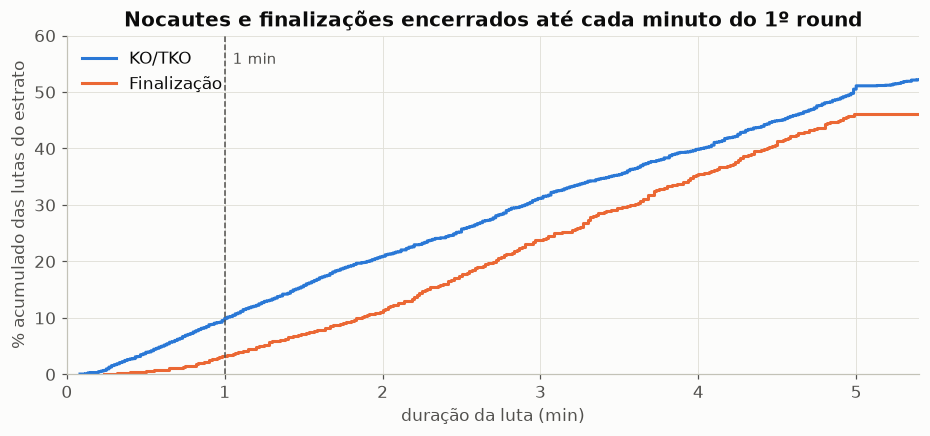

,lutas < 60 s,proporção
estrato,,
KO/TKO,178,0.095
Finalização,33,0.032
Decisão,0,0.0


In [12]:
DURACAO_MINIMA_S = 60

lutas["duracao_min"] = lutas.total_fight_seconds.astype(float) / 60

fig, ax = plt.subplots(figsize=(10, 4))
# Decisões duram no mínimo 15 min, então só nocautes e finalizações aparecem no 1º round.
for estrato in ["KO/TKO", "Finalização"]:
    d = np.sort(lutas.loc[lutas.estrato == estrato, "duracao_min"].to_numpy())
    ecdf = np.arange(1, len(d) + 1) / len(d) * 100
    ax.step(d, ecdf, where="post", color=COR_ESTRATO[estrato], label=estrato)
ax.axvline(DURACAO_MINIMA_S / 60, color=COR_TEXTO_2, linewidth=1, linestyle="--")
ax.text(DURACAO_MINIMA_S / 60 + 0.05, 55, "1 min", color=COR_TEXTO_2, fontsize=10)
ax.set_xlim(0, 5.4)
ax.set_ylim(0, 60)
ax.set_title("Nocautes e finalizações encerrados até cada minuto do 1º round")
ax.set_xlabel("duração da luta (min)")
ax.set_ylabel("% acumulado das lutas do estrato")
ax.legend(loc="upper left", frameon=False)
salvar(fig, "fig03_lutas_curtas")
plt.show()

curtas = lutas.total_fight_seconds < DURACAO_MINIMA_S
display(curtas.groupby(lutas.estrato, observed=True).agg(["sum", "mean"])
              .rename(columns={"sum": f"lutas < {DURACAO_MINIMA_S} s", "mean": "proporção"}).round(3))

lutas = lutas[~curtas]
funil.append((f"Com duração >= {DURACAO_MINIMA_S} s", lutas))

**Resultado.** **178 lutas de KO/TKO** (9,5% do estrato) e **33 finalizações** (3,2%) acabaram antes de 1 minuto; nenhuma decisão, por definição. Elas saem da análise. São as lutas com as taxas por minuto mais infladas, então o estrato KO/TKO fica menos extremo. O limiar de 60 s é uma escolha; a Seção 13 testa 30 s e 120 s.

## 3.7 Resumo da preparação

Funil completo, do recorte temporal à amostra analítica, e o tamanho final de cada estrato.

In [13]:
tabela_funil = pd.DataFrame(
    [(etapa, len(df), *(df["estrato"].value_counts().reindex(ESTRATOS).tolist() if "estrato" in df
                        else [pd.NA] * len(ESTRATOS))) for etapa, df in funil],
    columns=["etapa", "lutas", *ESTRATOS]).set_index("etapa")
tabela_funil["removidas"] = (tabela_funil["lutas"].shift() - tabela_funil["lutas"]).fillna(0).astype(int)
tabela_funil.astype("Int64")

,lutas,KO/TKO,Finalização,Decisão,removidas
etapa,,,,,
Lutas na janela (2015+),5849,<NA>,<NA>,<NA>,0
Com vencedor e método válido,5730,1865,1028,2837,119
Com estatísticas dos dois lutadores,5730,1865,1028,2837,0
Com tempo de controle dos dois,5730,1865,1028,2837,0
Com duração >= 60 s,5519,1687,995,2837,211


**Amostra analítica: 5.519 lutas**, sendo 2.837 decisões, 1.687 KO/TKO e 995 finalizações. São 24 vezes as 234 lutas de James et al. e todas têm o conjunto completo de estatísticas.

# 4. Unidade de análise e engenharia de atributos

## 4.1 Uma linha por luta, com lutador de referência sorteado

James et al. usaram duas linhas por luta (vencedor e perdedor), o que duplica cada confronto e faz o mesmo combate aparecer no treino e no teste. Aqui:

1. em cada estrato, **sorteamos metade das lutas** para ter o vencedor como lutador de referência; na outra metade, a referência é o perdedor (semente fixa `SEED`);
2. a variável resposta é **y = 1** se a referência venceu e **0** caso contrário;
3. cada atributo é uma **diferença** (referência − oponente).

Se a referência fosse sempre o vencedor, todas as diferenças seriam positivas e y seria constante. O sorteio dá y = 50% e elimina a duplicação espelhada.

Por que sortear **exatamente metade** em cada estrato, e não jogar uma moeda por luta? A moeda também funcionaria, mas por acaso pode desbalancear um estrato: com a semente 42, ela deu 52,4% de y = 1 nas decisões (teste binomial, p = 0,012). O sorteio balanceado elimina esse ruído sem criar viés, porque quais lutas recebem o vencedor como referência continua sendo aleatório.

**Consequência:** atributos que não são diferenças (categoria de peso, gênero, número de rounds, ano) não podem predizer y, pois a referência é aleatória. Eles entram só como **moderadores** (subamostras na Seção 13), nunca como efeitos principais.

## 4.2 Atributos por lutador (normalizados pela duração, em minutos)

| Bloco | Atributo | Definição |
|---|---|---|
| Grappling | `ground_pm` | golpes significativos no solo conectados / min |
| Grappling | `ctrl_share` | tempo de controle / duração da luta |
| Grappling | `td_pm` | quedas conectadas / min |
| Grappling | `td_acc` | quedas conectadas / tentadas (0 se não tentou) |
| Grappling | `td_sem_tentativa` | 1 se não tentou queda (categoria própria, não ausente) |
| Grappling | `sub_pm` | tentativas de finalização / min |
| Grappling | `rev` | reversões (variável rara: avaliar a distribuição antes de manter) |
| Striking | `dist_pm` | golpes significativos à distância conectados / min |
| Striking | `clinch_pm` | golpes significativos no clinch conectados / min |
| Striking | `total_pm` | golpes totais conectados / min |
| Striking | `sig_acc` | precisão de golpes significativos |
| Striking | `kd` | knockdowns |

Percentuais do site foram descartados pelo scraper: as precisões são recalculadas de `landed`/`attempted`.

> **Circularidade esperada:** `kd` e `ground_pm` são parte do desfecho em KO/TKO; `sub_pm` é parte do desfecho em finalizações. Isso não é um erro: é exatamente o mecanismo que a hipótese investiga.

In [14]:
GRAPPLING = ["ground_pm", "ctrl_share", "td_pm", "td_acc", "td_sem_tentativa", "sub_pm", "rev"]
STRIKING = ["dist_pm", "clinch_pm", "total_pm", "sig_acc", "kd"]
ATRIBUTOS = GRAPPLING + STRIKING

s = fight_stats[fight_stats.fight_id.isin(lutas.fight_id)].copy()
contagens = s.select_dtypes("number").columns
s[contagens] = s[contagens].astype(float)
minutos = s.fight_id.map(lutas.set_index("fight_id").duracao_min)

por_lutador = pd.DataFrame({
    "fight_id": s.fight_id,
    "fighter_id": s.fighter_id,
    "ground_pm": s.ground_landed / minutos,
    "ctrl_share": s.ctrl_seconds / (minutos * 60),
    "td_pm": s.td_landed / minutos,
    "td_acc": (s.td_landed / s.td_attempted).where(s.td_attempted > 0, 0.0),
    "td_sem_tentativa": (s.td_attempted == 0).astype(float),
    "sub_pm": s.sub_att / minutos,
    "rev": s.rev,
    "dist_pm": s.distance_landed / minutos,
    "clinch_pm": s.clinch_landed / minutos,
    "total_pm": s.total_str_landed / minutos,
    "sig_acc": (s.sig_str_landed / s.sig_str_attempted).where(s.sig_str_attempted > 0, 0.0),
    "kd": s.kd,
})
por_lutador = por_lutador.merge(lutas[["fight_id", "winner_id", "estrato"]], on="fight_id")
por_lutador["venceu"] = (por_lutador.fighter_id == por_lutador.winner_id).astype(int)

assert por_lutador[ATRIBUTOS].notna().all().all()
print(f"{len(por_lutador):,} linhas (lutador x luta) para {por_lutador.fight_id.nunique():,} lutas")
por_lutador[ATRIBUTOS].describe().T.round(3)

11,038 linhas (lutador x luta) para 5,519 lutas


,count,mean,std,min,25%,50%,75%,max
ground_pm,11038.0,0.552,1.305,0.0,0.000,0.067,0.533,22.810
ctrl_share,11038.0,0.190,0.223,0.0,0.013,0.098,0.302,0.987
td_pm,11038.0,0.097,0.163,0.0,0.000,0.000,0.133,2.297
td_acc,11038.0,0.253,0.341,0.0,0.000,0.000,0.500,1.000
td_sem_tentativa,11038.0,0.336,0.472,0.0,0.000,0.000,1.000,1.000
sub_pm,11038.0,0.041,0.121,0.0,0.000,0.000,0.000,2.449
rev,11038.0,0.129,0.418,0.0,0.000,0.000,0.000,6.000
dist_pm,11038.0,2.976,2.218,0.0,1.333,2.560,4.120,38.769
clinch_pm,11038.0,0.444,0.686,0.0,0.000,0.205,0.600,11.250
total_pm,11038.0,5.434,3.205,0.0,3.333,4.867,6.904,38.769


**Reversões são raras?** A tabela abaixo mostra a distribuição de `rev` por lutador e a proporção de lutas em que os dois lutadores têm o mesmo número de reversões (diferença zero).

In [15]:
display(por_lutador.rev.value_counts().sort_index().to_frame("lutadores"))
dif_rev = por_lutador.groupby("fight_id").rev.agg(lambda r: r.iloc[0] - r.iloc[1])
print(f"Lutas com diferença de reversões = 0: {100 * (dif_rev == 0).mean():.1f}%")

,lutadores
rev,
0.0,9877
1.0,958
2.0,157
3.0,36
4.0,6
5.0,3
6.0,1


Lutas com diferença de reversões = 0: 85.0%


**Decisão.** 89,5% dos lutadores não têm nenhuma reversão e, em 85% das lutas, a diferença entre os dois é zero. A variável é mantida como contagem (diferença entre −6 e 6), mas deve pesar pouco; a Seção 11 verifica se a seleção de atributos a descarta.

In [16]:
rng = np.random.default_rng(SEED)
lutas["y"] = 0
for estrato, idx in lutas.groupby("estrato", observed=True).groups.items():
    sorteadas = rng.permutation(np.asarray(idx))[: len(idx) // 2]
    lutas.loc[sorteadas, "y"] = 1

perdedor_id = np.where(lutas.winner_id == lutas.fighter_a_id, lutas.fighter_b_id, lutas.fighter_a_id)
lutas["ref_id"] = np.where(lutas.y == 1, lutas.winner_id, perdedor_id)
lutas["opp_id"] = np.where(lutas.y == 1, perdedor_id, lutas.winner_id)

valores = por_lutador.set_index(["fight_id", "fighter_id"])[ATRIBUTOS]
ref = valores.loc[list(zip(lutas.fight_id, lutas.ref_id))].to_numpy()
opp = valores.loc[list(zip(lutas.fight_id, lutas.opp_id))].to_numpy()

COLUNAS_META = ["fight_id", "date", "ano", "estrato", "method", "weight_class", "is_women",
                "is_title_fight", "scheduled_rounds", "duracao_min", "ref_id", "opp_id", "winner_id", "y"]
dataset = lutas[COLUNAS_META].reset_index(drop=True)
dataset[ATRIBUTOS] = ref - opp
# bool[pyarrow] comparado com int dá sempre False; por isso a conversão para numpy.
assert (dataset.y.to_numpy() == (dataset.winner_id == dataset.ref_id).to_numpy(dtype=bool)).all()

balanco = dataset.groupby("estrato", observed=True).agg(lutas=("y", "size"), pct_ref_venceu=("y", "mean"))
balanco["pct_ref_venceu"] = (100 * balanco.pct_ref_venceu).round(1)
balanco["pct_A_venceu"] = (100 * lutas.groupby("estrato", observed=True)
                           .apply(lambda d: (d.winner_id == d.fighter_a_id).mean())).round(1)
display(balanco)

dataset.to_parquet(RESULTS_DIR / "dataset_lutas.parquet", index=False)
por_lutador.to_parquet(RESULTS_DIR / "por_lutador.parquet", index=False)
dataset.head()

,lutas,pct_ref_venceu,pct_A_venceu
estrato,,,
KO/TKO,1687,50.0,55.5
Finalização,995,49.9,59.7
Decisão,2837,50.0,57.3


,fight_id,date,ano,estrato,method,weight_class,is_women,is_title_fight,scheduled_rounds,duracao_min,ref_id,opp_id,winner_id,y,ground_pm,ctrl_share,td_pm,td_acc,td_sem_tentativa,sub_pm,rev,dist_pm,clinch_pm,total_pm,sig_acc,kd
0,810c9da07970c4a6,2022-09-03,2022,KO/TKO,KO/TKO,Heavyweight,False,False,5,14.383333,787bb1f087ccff8a,c62fbc117d57b943,787bb1f087ccff8a,1,0.000000,-0.003476,0.000000,0.000000,-1.0,0.000000,0.0,5.701043,-0.069525,5.631518,0.328919,0.0
1,b8ca1acdf3dc2f58,2022-09-03,2022,Decisão,U-DEC,Middleweight,False,False,3,15.000000,e1147d3d2dabe1ce,7acbb0972e75281a,e1147d3d2dabe1ce,1,0.133333,-0.017778,0.066667,1.000000,0.0,0.000000,0.0,2.600000,0.000000,2.400000,0.161300,0.0
2,20f316f96c9e4458,2022-09-03,2022,Decisão,U-DEC,Middleweight,False,False,3,15.000000,b9437600497350f3,881bf86d4cba8578,881bf86d4cba8578,0,-0.466667,-0.230000,-0.133333,-0.285714,0.0,-0.133333,0.0,0.533333,-0.400000,-0.866667,-0.203522,0.0
3,1a191251620a84ca,2022-09-03,2022,KO/TKO,KO/TKO,Middleweight,False,False,3,11.150000,9d83f6da776ff7d6,77d7295d1b22c694,9d83f6da776ff7d6,1,0.000000,-0.091181,0.000000,0.000000,1.0,0.000000,0.0,1.524664,0.269058,2.062780,0.174083,1.0
4,398db40015b3c81c,2022-09-03,2022,Decisão,M-DEC,Featherweight,False,False,3,15.000000,082eba4cd80f736f,e1d40e8782d80bc2,e1d40e8782d80bc2,0,-0.200000,-0.522222,-0.200000,-0.600000,0.0,0.066667,0.0,-0.800000,0.200000,-2.533333,-0.079784,0.0


**Resultado.** Cada estrato tem y = 1 em metade das lutas (50,0% ou a metade arredondada para baixo em estratos ímpares), enquanto o lutador A teria vencido entre 55% e 60%. O conjunto de modelagem (uma linha por luta, 12 diferenças, y e metadados) está em `results/dataset_lutas.parquet`; os valores por lutador, usados nas comparações vencedor × perdedor, em `results/por_lutador.parquet`.

# 5. Estatística descritiva

## 5.1 Perfil dos estratos

In [17]:
perfil = dataset.groupby("estrato", observed=True).agg(
    lutas=("y", "size"),
    duracao_media_min=("duracao_min", "mean"),
    duracao_mediana_min=("duracao_min", "median"),
    pct_feminino=("is_women", "mean"),
    pct_5_rounds=("scheduled_rounds", lambda r: (r == 5).mean()),
    pct_titulo=("is_title_fight", "mean"),
)
for col in ["pct_feminino", "pct_5_rounds", "pct_titulo"]:
    perfil[col] *= 100
perfil["pct_da_amostra"] = 100 * perfil.lutas / perfil.lutas.sum()
perfil.round(1)

,lutas,duracao_media_min,duracao_mediana_min,pct_feminino,pct_5_rounds,pct_titulo,pct_da_amostra
estrato,,,,,,,
KO/TKO,1687,6.7,5.8,8.1,13.3,5.0,30.6
Finalização,995,7.0,6.6,17.3,8.6,4.3,18.0
Decisão,2837,15.8,15.0,19.8,8.1,3.9,51.4


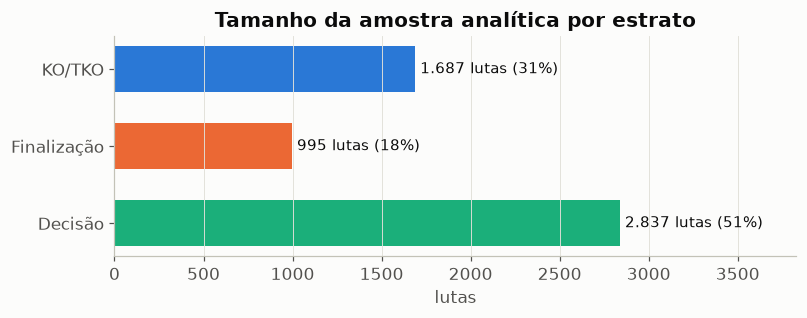

In [18]:
fig, ax = plt.subplots(figsize=(8, 2.6))
n = perfil.lutas.reindex(ESTRATOS[::-1])
ax.barh(n.index, n.values, height=0.6, color=[COR_ESTRATO[e] for e in n.index])
for i, v in enumerate(n.values):
    ax.text(v + 30, i, f"{v:,} lutas ({100 * v / n.sum():.0f}%)".replace(",", "."), va="center", color=COR_TEXTO, fontsize=10)
ax.set_xlim(0, n.max() * 1.35)
ax.grid(axis="y", visible=False)
ax.set_title("Tamanho da amostra analítica por estrato")
ax.set_xlabel("lutas")
salvar(fig, "fig04_tamanho_estratos")
plt.show()

**Resultado.**
- As **decisões são metade da amostra** (51%); finalizações, 18%.
- Nocautes e finalizações duram em média **7 minutos**; decisões, **15,8** (3 rounds completos, ou 25 min nas lutas de 5 rounds).
- **Lutas femininas** são 20% das decisões e 17% das finalizações, mas só **8% dos nocautes**. Como o gênero se distribui de forma desigual entre os estratos, a Seção 13 repete a análise só com lutas masculinas.
- Lutas de 5 rounds e de título são um pouco mais frequentes entre os nocautes (13% e 5%).

## 5.2 Atributos por lutador: vencedores × perdedores

**Médias** de cada atributo por estrato, separando vencedores (V) e perdedores (P). Usamos médias porque a mediana é zero para a maioria dos atributos de grappling (Seção 5.3). A coluna **V/P** divide a média do vencedor pela do perdedor: 2 significa que o vencedor fez o dobro.

In [19]:
medias = por_lutador.groupby(["estrato", "venceu"], observed=True)[ATRIBUTOS].mean().T
medias.columns = [f"{e} | {'V' if v else 'P'}" for e, v in medias.columns]
for e in ESTRATOS:
    medias[f"{e} | V/P"] = medias[f"{e} | V"] / medias[f"{e} | P"]
medias = medias[[f"{e} | {k}" for e in ESTRATOS for k in ["V", "P", "V/P"]]]
medias.round(3)

,KO/TKO | V,KO/TKO | P,KO/TKO | V/P,Finalização | V,Finalização | P,Finalização | V/P,Decisão | V,Decisão | P,Decisão | V/P
ground_pm,1.774,0.127,13.996,0.934,0.262,3.570,0.469,0.127,3.682
ctrl_share,0.184,0.103,1.781,0.398,0.152,2.616,0.257,0.119,2.165
td_pm,0.080,0.058,1.378,0.245,0.080,3.057,0.126,0.057,2.202
td_acc,0.215,0.133,1.614,0.471,0.199,2.364,0.350,0.193,1.816
td_sem_tentativa,0.543,0.473,1.148,0.212,0.496,0.427,0.188,0.266,0.707
sub_pm,0.016,0.014,1.140,0.295,0.018,16.592,0.020,0.015,1.361
rev,0.073,0.043,1.708,0.144,0.113,1.277,0.177,0.167,1.061
dist_pm,4.160,2.870,1.449,2.194,1.923,1.141,3.333,2.622,1.271
clinch_pm,0.688,0.352,1.956,0.423,0.327,1.294,0.491,0.357,1.375
total_pm,8.119,4.090,1.985,5.778,3.741,1.544,6.217,4.328,1.436


**Resultado.**
- **KO/TKO.** O vencedor acerta em média **1,77 golpe no solo por minuto**, contra 0,13 do perdedor (14 vezes mais), e tem 0,85 knockdown contra 0,05. Já quedas (0,080 × 0,058 por minuto) e controle (18% × 10% do tempo) mudam pouco. O "grappling" dos nocautes é quase só o *ground and pound* final, isto é, o próprio nocaute.
- **Finalização.** O vencedor controla **40% do tempo** (perdedor: 15%) e derruba 3 vezes mais. As tentativas de finalização (0,295 × 0,018 por minuto) são parte do desfecho.
- **Decisão.** O grappling **continua separando**: controle de 26% × 12% do tempo (2,2 vezes), golpes no solo 3,7 vezes e quedas 2,2 vezes. O striking à distância separa menos (3,33 × 2,62 por minuto; 1,3 vez).

**Primeiro sinal para a hipótese:** pelas médias, a vantagem do grappling **não desaparece** nas decisões. Ela é bem menor que nos nocautes só nos golpes no solo, e é **maior** que nos nocautes no controle e nas quedas. São médias brutas, sem teste e sem controlar as outras variáveis; a confirmação vem nas Seções 6 e 8.

## 5.3 Assimetria e excesso de zeros

Contagens de eventos raros (knockdowns, finalizações, reversões) têm muitos zeros e caudas longas. Isso pesa na escolha de modelos e transformações (Seção 11).

In [20]:
CONTINUOS = [a for a in ATRIBUTOS if a != "td_sem_tentativa"]
forma = pd.DataFrame({
    "pct_zeros": 100 * (por_lutador[CONTINUOS] == 0).mean(),
    "assimetria": por_lutador[CONTINUOS].skew(),
    "p99": por_lutador[CONTINUOS].quantile(0.99),
    "máximo": por_lutador[CONTINUOS].max(),
})
zeros_estrato = (por_lutador.groupby("estrato", observed=True)[CONTINUOS]
                 .agg(lambda c: 100 * (c == 0).mean()).T.add_prefix("pct_zeros | "))
forma.join(zeros_estrato).round(2)

,pct_zeros,assimetria,p99,máximo,pct_zeros | KO/TKO,pct_zeros | Finalização,pct_zeros | Decisão
ground_pm,46.71,5.67,6.27,22.81,48.10,50.50,44.55
ctrl_share,15.95,1.32,0.86,0.99,23.06,17.49,11.19
td_pm,54.76,3.03,0.73,2.30,72.02,50.10,46.12
td_acc,54.76,1.09,1.00,1.00,72.02,50.10,46.12
sub_pm,78.82,5.53,0.60,2.45,92.15,45.78,82.48
rev,89.48,4.19,2.00,6.00,95.23,89.15,86.18
dist_pm,1.75,1.73,9.89,38.77,1.69,6.58,0.09
clinch_pm,27.72,4.14,3.06,11.25,39.63,44.12,14.89
total_pm,0.43,1.83,16.33,38.77,0.62,1.36,0.00
sig_acc,0.80,0.12,0.83,1.00,0.80,3.07,0.00


**Resultado.**
- **Excesso de zeros.** 89% dos lutadores não têm reversões, 82% não têm knockdowns, 79% não tentam finalizar, 55% não conseguem nenhuma queda e 47% não acertam golpes no solo. A variável binária `td_sem_tentativa` ficou fora da tabela: 34% dos lutadores não tentaram nenhuma queda.
- **Caudas longas.** Golpes no solo têm assimetria de 5,7 e máximo de 22,8 por minuto, contra 6,3 no percentil 99.
- **Consequências.** Médias e desvios-padrão (base do Cohen's *d*) são sensíveis às caudas. Por isso a Seção 6 usa também a probabilidade de superioridade, que só depende da ordem dos valores, e a Seção 11 testa transformações (`log1p`, quantis).

# 6. Análise exploratória: há algum padrão?

Antes de qualquer modelagem formal, esta seção examina visualmente os dados para responder: há sinais observáveis de que a vantagem de grappling difere entre estratos de término de luta? 

Percorremos sete ângulos complementares: evolução temporal, duração, comparação vencedor/perdedor, correlação entre indicadores, tamanho de efeito (Cohen's *d*), probabilidade de superioridade e viés de seleção. Cada um responde uma pergunta diferente e, juntos, constroem a base empírica para a hipótese H3.

## 6.1 Como as lutas terminam ao longo do tempo

O primeiro passo é entender se a composição dos estratos mudou ao longo da história do UFC. Uma tendência de mais decisões ao longo do tempo, por exemplo, pode indicar evolução tática (luta mais defensiva) ou mudanças de regras. Essa dinâmica temporal é importante para evitar confundidores ao comparar estratos.


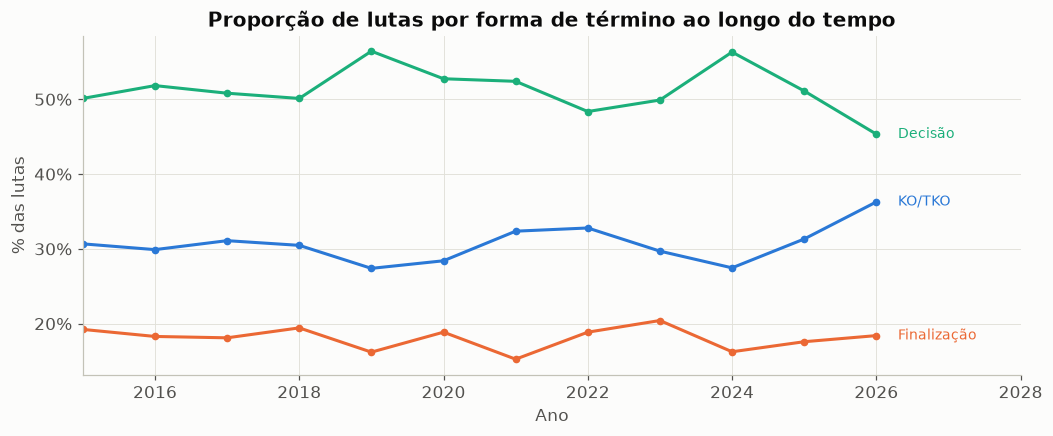

In [21]:
# Proporção de cada estrato por ano
prop_ano = (
    dataset.groupby(["ano", "estrato"], observed=True)
    .size()
    .unstack(fill_value=0)
    .reindex(columns=ESTRATOS, fill_value=0)
)
prop_ano = prop_ano.div(prop_ano.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(figsize=(11, 4))
for estrato in ESTRATOS:
    ax.plot(
        prop_ano.index, prop_ano[estrato],
        label=estrato, color=COR_ESTRATO[estrato],
        marker="o", markersize=4, linewidth=2,
    )
    # Rótulo direto na última observação
    ax.text(
        prop_ano.index[-1] + 0.3, prop_ano[estrato].iloc[-1],
        estrato, color=COR_ESTRATO[estrato], va="center", fontsize=9,
    )

ax.set_xlabel("Ano")
ax.set_ylabel("% das lutas")
ax.set_title("Proporção de lutas por forma de término ao longo do tempo")
ax.set_xlim(prop_ano.index.min(), prop_ano.index.max() + 2)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0f}%"))
ax.grid(axis="y", color=COR_GRADE, linewidth=0.6)
ax.set_facecolor(COR_FUNDO)
fig.patch.set_facecolor(COR_FUNDO)
ax.spines[["top", "right"]].set_visible(False)
salvar(fig, "fig05_prop_estrato_ano")
plt.show()


**Resultado.** Entre 2015 e 2025, a proporção de decisões oscila entre cerca de 48% e 56% das lutas do ano, sem tendência clara. Finalizações ficam quase sempre entre 15% e 20%. KO/TKO varia entre cerca de 27% e 33% e sobe para cerca de 36% em 2026. Esse último ano tem só o período até setembro, e a queda da decisão nele (para cerca de 45%) deve ser lida com cautela, porque a amostra é menor.

**Leitura.** Os dados não sustentam a ideia de que as decisões estejam crescendo ao longo do tempo. A participação delas é praticamente estável na década, o que reduz o risco de confundir estrato com época nas comparações seguintes.

## 6.2 Duração das lutas por estrato

A duração da luta é uma variável de confundimento crítica: indicadores expressos por minuto (golpes/min, quedas/min) são inflados em lutas muito curtas. KO/TKOs tipicamente encerram cedo, enquanto decisões vão ao limite dos 3 ou 5 rounds. Se ignorarmos isso, compararemos taxas medidas em janelas de tempo muito diferentes.

Na Seção 3.6 optamos por **não** dividir por duração, mas sim usar contagens totais normalizadas pelo número de rounds escalado. Este gráfico confirma que a escolha é justificada: a distribuição de duração difere substancialmente entre estratos.


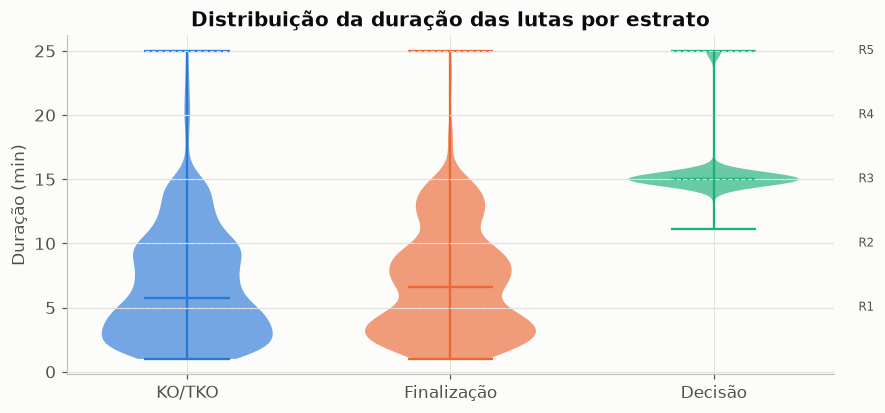

              count  mean  std   min   25%   50%   75%   max
estrato                                                     
KO/TKO       1687.0   6.7  4.4   1.0   3.1   5.8   9.6  25.0
Finalização   995.0   7.0  4.3   1.0   3.3   6.6   9.5  25.0
Decisão      2837.0  15.8  2.7  11.1  15.0  15.0  15.0  25.0


In [22]:
fig, ax = plt.subplots(figsize=(9, 4))

positions = list(range(len(ESTRATOS)))
for i, estrato in enumerate(ESTRATOS):
    vals = dataset.loc[dataset.estrato == estrato, "duracao_min"].dropna()
    parts = ax.violinplot(
        vals, positions=[i], widths=0.65,
        showmedians=True, showextrema=True,
    )
    for pc in parts["bodies"]:
        pc.set_facecolor(COR_ESTRATO[estrato])
        pc.set_alpha(0.65)
    for key in ["cmedians", "cmins", "cmaxes", "cbars"]:
        parts[key].set_color(COR_ESTRATO[estrato])
        parts[key].set_linewidth(1.5)

# Linhas de referência de fim de round
for yval, label in [(5, "R1"), (10, "R2"), (15, "R3"), (20, "R4"), (25, "R5")]:
    ax.axhline(yval, color=COR_GRADE, linewidth=0.8, linestyle="--")
    ax.text(len(ESTRATOS) - 0.5 + 0.05, yval, label, va="center",
            fontsize=8, color=COR_TEXTO_2)

ax.set_xticks(positions)
ax.set_xticklabels(ESTRATOS)
ax.set_ylabel("Duração (min)")
ax.set_title("Distribuição da duração das lutas por estrato")
ax.set_facecolor(COR_FUNDO)
fig.patch.set_facecolor(COR_FUNDO)
ax.spines[["top", "right"]].set_visible(False)
salvar(fig, "fig06_duracao_estrato")
plt.show()

# Resumo numérico
print(dataset.groupby("estrato", observed=True)["duracao_min"]
      .describe().round(1).to_string())


**Resultado.** A duração varia muito entre os estratos. KO/TKO tem mediana de 5,8 min e Finalização, de 6,6 min, e os 75% superiores dos dois estratos ficam abaixo de 10 min. Nas decisões, a mediana é de 15,0 min e os quartis também são 15,0 min, ou seja, pelo menos metade das lutas dura exatamente 15 minutos (três rounds de cinco minutos). O violino mostra essa concentração logo acima de R3, com uma cauda que chega a 25 min (cinco rounds).

**Leitura.** Como as durações são tão diferentes, comparar indicadores por minuto entre estratos mistura o efeito da tática com o efeito do tempo de luta. Por isso o estrato, e não a duração, é a unidade de comparação das subseções seguintes.

## 6.3 Vencedores × perdedores em cada estrato

Comparar diretamente os indicadores de vencedores e perdedores dentro de cada estrato é o teste visual mais direto da hipótese. Se grappling separa bem em KO/TKO e Finalização mas pouco em Decisão, as caixas de vencedores e perdedores devem ser mais próximas neste último estrato.

Usamos `por_lutador`, que tem **uma linha por lutador por luta** (par ref/oponente já separado), com a coluna `venceu` indicando o resultado. As quatro variáveis escolhidas representam os principais grupos: grappling ofensivo (`ground_pm`), tempo de controle (`ctrl_share`), quedas (`td_pm`) e striking a distância (`dist_pm`).


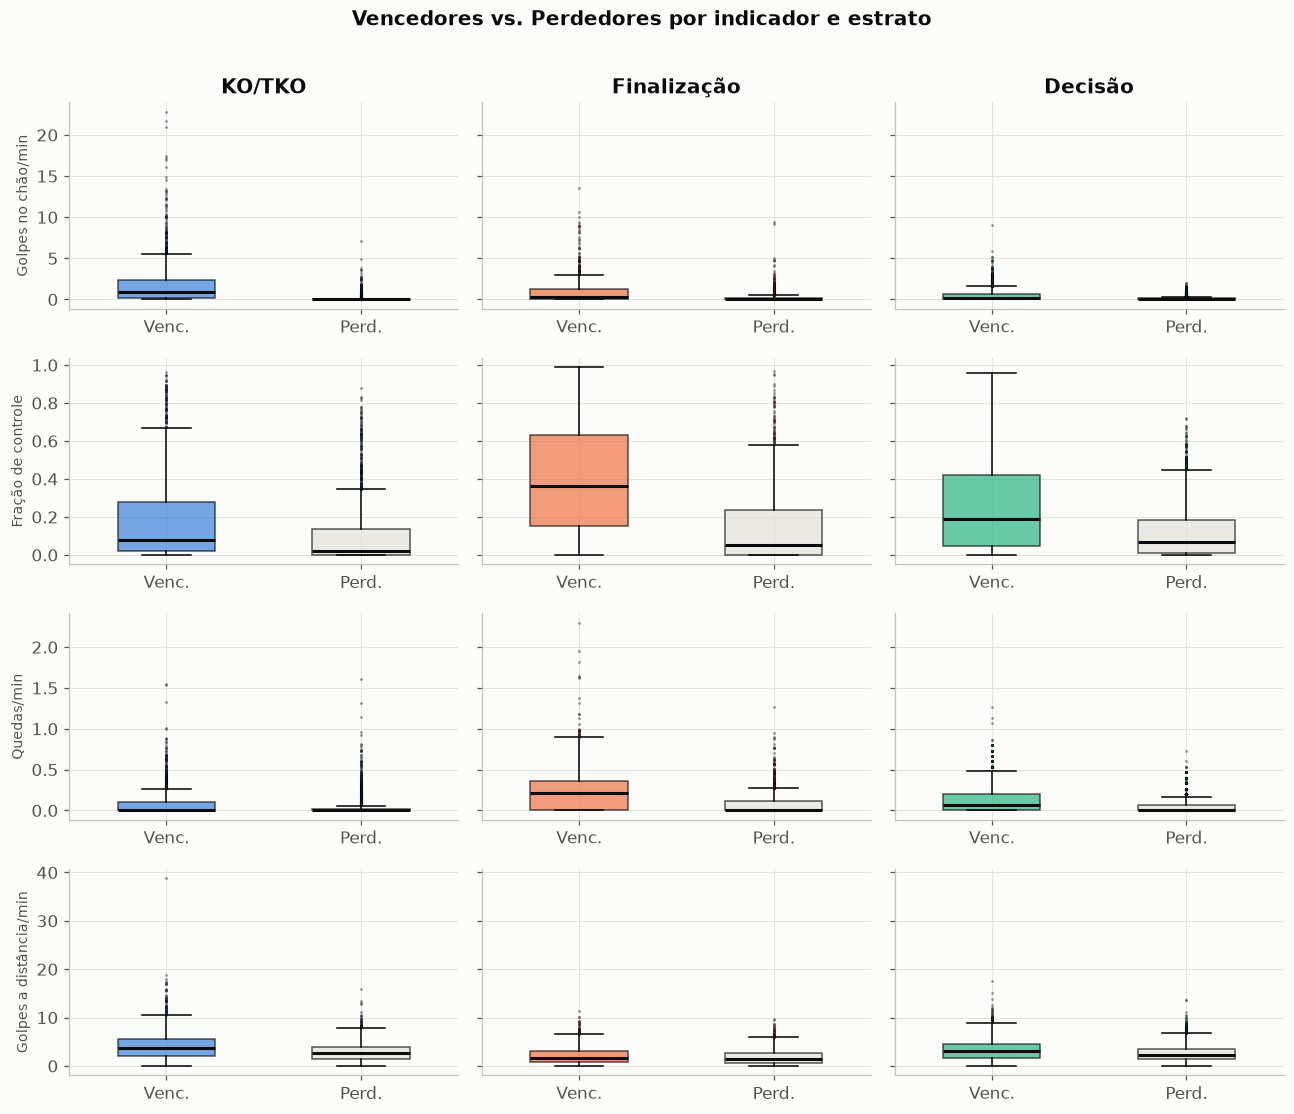

In [24]:
chave_vars = ["ground_pm", "ctrl_share", "td_pm", "dist_pm"]
rotulos_vars = {
    "ground_pm": "Golpes no chão/min",
    "ctrl_share": "Fração de controle",
    "td_pm": "Quedas/min",
    "dist_pm": "Golpes a distância/min",
}

fig, axes = plt.subplots(
    len(chave_vars), len(ESTRATOS),
    figsize=(12, 10), sharey="row",
)

for row, var in enumerate(chave_vars):
    for col, estrato in enumerate(ESTRATOS):
        ax = axes[row][col]
        sub = por_lutador[por_lutador.estrato == estrato]
        vencedores = sub.loc[sub.venceu == 1, var].dropna()
        perdedores = sub.loc[sub.venceu == 0, var].dropna()

        bplot = ax.boxplot(
            [vencedores, perdedores],
            tick_labels=["Venc.", "Perd."],
            patch_artist=True,
            medianprops=dict(color=COR_TEXTO, linewidth=2),
            flierprops=dict(marker=".", markersize=2, alpha=0.3,
                            markerfacecolor=COR_ESTRATO[estrato]),
            widths=0.5,
        )
        colors = [COR_ESTRATO[estrato], COR_GRADE]
        for patch, color in zip(bplot["boxes"], colors):
            patch.set_facecolor(color)
            patch.set_alpha(0.65)

        if row == 0:
            ax.set_title(estrato, fontweight="bold")
        if col == 0:
            ax.set_ylabel(rotulos_vars[var], fontsize=9)
        ax.set_facecolor(COR_FUNDO)
        ax.spines[["top", "right"]].set_visible(False)

fig.patch.set_facecolor(COR_FUNDO)
fig.suptitle("Vencedores vs. Perdedores por indicador e estrato",
             fontsize=13, fontweight="bold", y=1.01)
fig.tight_layout()
salvar(fig, "fig07_boxplot_venc_perd")
plt.show()


**Resultado.** Em todos os três estratos, a mediana de cada indicador é maior entre os vencedores, mas a separação varia:

- **Golpes no chão/min:** em KO/TKO, a caixa dos vencedores fica claramente acima de zero e a dos perdedores fica colada em zero. Em Decisão, a diferença aparece sobretudo na cauda superior, pois as duas caixas encostam em zero.
- **Fração de controle:** as medianas de vencedores ficam perto de 0,08 (KO/TKO), 0,37 (Finalização) e 0,19 (Decisão), contra valores próximos de 0,02, 0,05 e 0,07 para perdedores.
- **Quedas/min:** em KO/TKO, a mediana é zero para os dois grupos. Em Finalização e Decisão, os vencedores têm mediana acima de zero.
- **Golpes a distância/min:** os vencedores têm mediana maior nos três estratos, com diferença mais visível em KO/TKO e Decisão.

**Leitura.** A separação entre vencedores e perdedores existe nos três estratos, mas em Decisão as distribuições se sobrepõem mais nos indicadores de grappling. Quedas e controle ficam relativamente mais informativos em Decisão do que em KO/TKO, o que a subseção 6.5 quantifica. As distribuições também são muito assimétricas, com muitos zeros e caudas longas, o que justifica medidas não paramétricas como a probabilidade de superioridade (6.6).

## 6.4 Correlação e redundância entre atributos

Antes de calcular tamanhos de efeito e treinar modelos, é importante entender como os indicadores se relacionam entre si. Correlações altas entre preditores (multicolinearidade) não invalidam a exploração, mas podem inflar erros-padrão em regressões e dificultar a interpretação de importâncias individuais.

O **mapa de calor** abaixo mostra as correlações de Pearson entre as *diferenças* (ref − oponente) dos 12 indicadores, calculadas sobre o conjunto completo de lutas. O **VIF** (Fator de Inflação da Variância) quantifica o grau de redundância: valores acima de 10 indicam multicolinearidade severa.

Uma suspeita particular: `total_pm` (total de golpes/min) contém `dist_pm` (golpes à distância), `clinch_pm` (golpes no clinch) e `ground_pm` (golpes no chão), que somam os golpes significativos, e por isso pode ter VIF elevado. Verificaremos se mantê-lo ou removê-lo é a decisão correta.


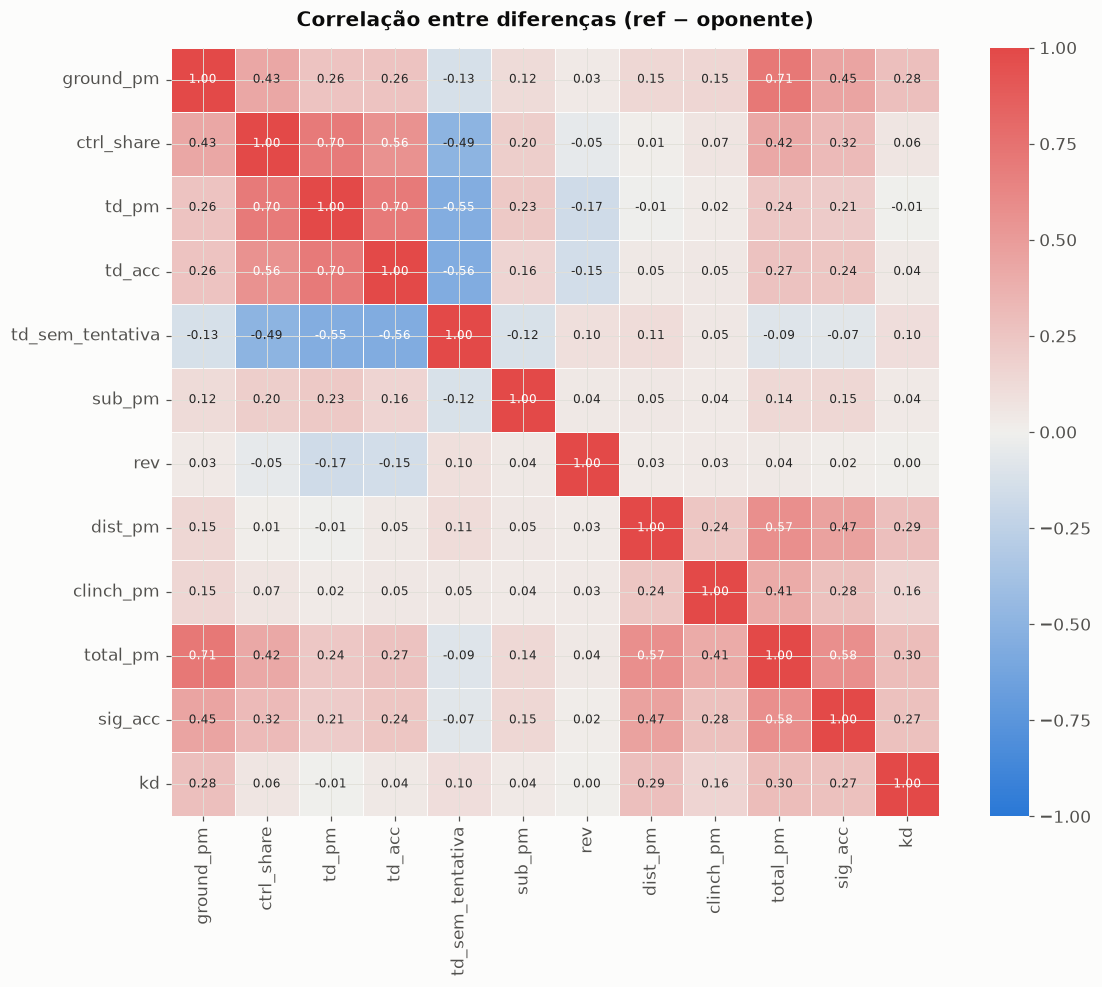

Fator de Inflação da Variância (VIF) dos indicadores:


,Atributo,VIF
0,total_pm,5.1
1,ground_pm,3.0
2,td_pm,2.9
3,ctrl_share,2.6
4,dist_pm,2.4
5,td_acc,2.2
6,sig_acc,1.7
7,td_sem_tentativa,1.7
8,clinch_pm,1.3
9,kd,1.2


In [ ]:
import seaborn as sns
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Mapa de calor de correlação
corr = dataset[ATRIBUTOS].corr()

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(
    corr,
    cmap=DIVERGENTE,
    center=0, vmin=-1, vmax=1,
    annot=True, fmt=".2f",
    linewidths=0.4, linecolor=COR_FUNDO,
    square=True, ax=ax,
    annot_kws={"size": 8},
)
ax.set_title("Correlação entre diferenças (ref − oponente)", pad=14)
ax.set_facecolor(COR_FUNDO)
fig.patch.set_facecolor(COR_FUNDO)
fig.tight_layout()
salvar(fig, "fig08_correlacao_atributos")
plt.show()

# VIF (Variance Inflation Factor) para detectar multicolinearidade
X_vif = dataset[ATRIBUTOS].dropna()
vif_df = pd.DataFrame({
    "Atributo": ATRIBUTOS,
    "VIF": [
        variance_inflation_factor(X_vif.values, i)
        for i in range(len(ATRIBUTOS))──────────────────────────────────────────────────────────────────────
    ],
}).sort_values("VIF", ascending=False).reset_index(drop=True)

print("Fator de Inflação da Variância (VIF) dos indicadores:")
display(vif_df.style.bar(subset=["VIF"], color="#2a78d6", vmin=0).format({"VIF": "{:.1f}"}))


**Resultado.** O mapa de calor não mostra nenhum par de indicadores distintos com correlação próxima de 1. As correlações mais altas são:

- `ground_pm` × `total_pm`: 0,71
- `ctrl_share` × `td_pm`: 0,70, e `td_pm` × `td_acc`: 0,70
- `total_pm` × `sig_acc`: 0,58, e `dist_pm` × `total_pm`: 0,57
- `td_sem_tentativa` × `td_pm`: −0,55

O VIF fica abaixo de 10 para todos os indicadores. O maior valor é o de `total_pm` (5,1), seguido de `ground_pm` (3,0) e `td_pm` (2,9).

**Leitura.** Correlações de 0,7 são moderadas, e não indicam redundância severa por si só: r = 0,7 corresponde a cerca de 49% de variância compartilhada, e o VIF de um par assim seria próximo de 2. Não há motivo para remover indicadores apenas com base nessas correlações. O efeito é sobre a interpretação dos coeficientes individuais: `ctrl_share` e `td_pm` (0,70), e `td_pm` e `td_acc` (0,70), medem em parte o mesmo aspecto da luta, então seus efeitos separados têm erros-padrão maiores. Isso pesa sobretudo nos testes da Seção 8 que envolvem esses pares.

O VIF de `total_pm` (5,1) fica acima do limiar usual de 5, mas abaixo de 10, o que o torna o indicador mais redundante do conjunto. Sua correlação com `ground_pm` (0,71) é esperada, porque ambos contam golpes no chão. Não se trata de duplicação por construção: `total_pm` não é a soma de `dist_pm`, `clinch_pm` e `ground_pm`. Pela verificação da Seção 3, esses três somam os golpes significativos (`sig_str`), que estão contidos no total de golpes, e este também inclui golpes não significativos. Por isso o VIF é finito. A definição de `total_pm` na Seção 4 é consistente com essa verificação.

## 6.5 Tamanho de efeito por estrato (figura principal 1)

Replicamos a Figura 1 de James et al. (Cohen's *d* entre vencedores e perdedores), agora **separada por estrato**. Intervalos de confiança de 95% por bootstrap **sobre lutas** (reamostrando lutas, não linhas, para respeitar o pareamento).

**Interpretação de Cohen's *d*:** mede quantos desvios-padrão separam as médias dos dois grupos. Convencionalmente, |d| ≥ 0.2 é pequeno, ≥ 0.5 é médio, ≥ 0.8 é grande. Um d próximo de zero significa que o indicador não discrimina vencedores de perdedores naquele estrato.

Se H3 for verdadeira, esperamos que os indicadores de **grappling** (especialmente `ground_pm`) mostrem d alto em KO/TKO e Finalização, mas muito menor em Decisão, enquanto `dist_pm` recupera importância relativa nas decisões.


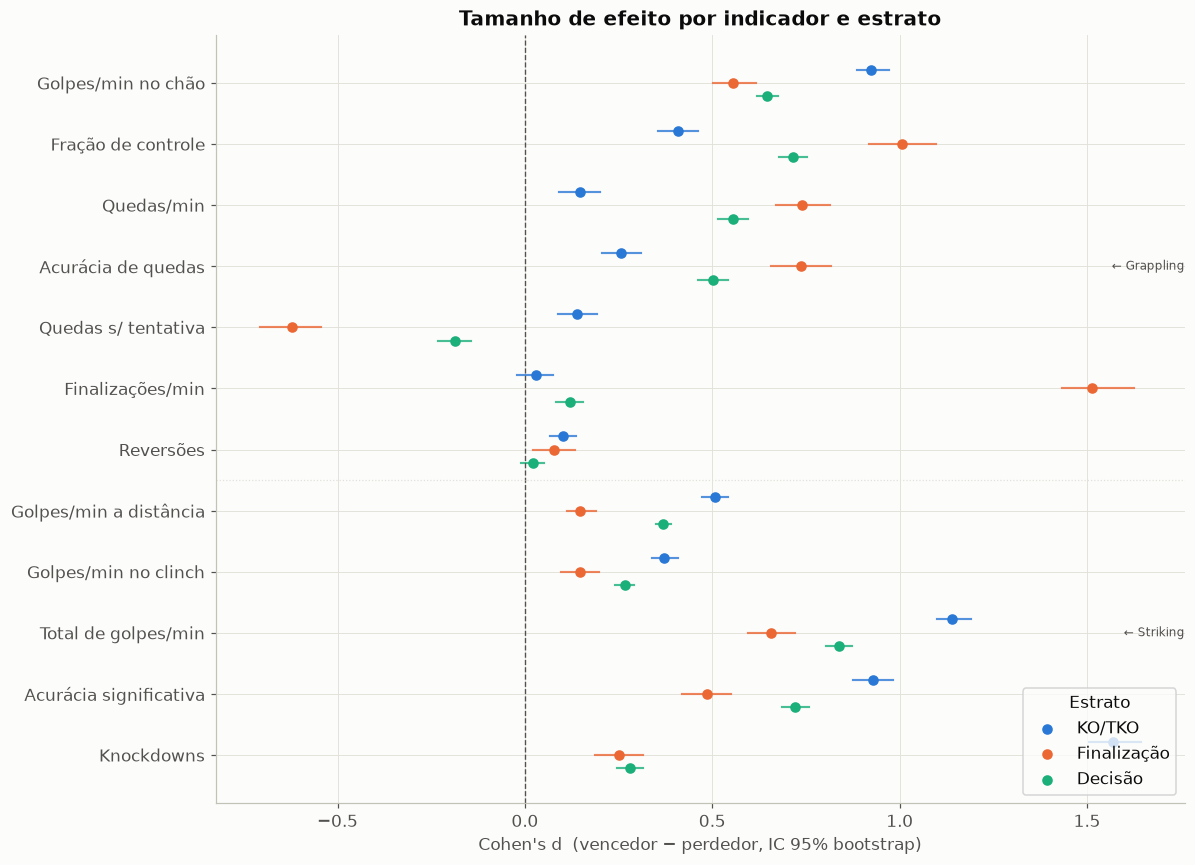


Cohen's d observado por indicador e estrato:


estrato,Decisão,Finalização,KO/TKO
atributo,,,
ground_pm,0.646000,0.556000,0.924000
ctrl_share,0.716000,1.005000,0.408000
td_pm,0.556000,0.738000,0.146000
td_acc,0.503000,0.736000,0.256000
td_sem_tentativa,-0.187000,-0.623000,0.140000
sub_pm,0.120000,1.512000,0.029000
rev,0.021000,0.077000,0.103000
dist_pm,0.369000,0.148000,0.507000
clinch_pm,0.266000,0.148000,0.372000


In [26]:
rng = np.random.default_rng(SEED)
N_BOOT = 1_000

def cohens_d_arr(a, b):
    """Cohen's d entre arrays a (vencedores) e b (perdedores)."""
    n1, n2 = len(a), len(b)
    if n1 < 2 or n2 < 2:
        return np.nan
    pooled = np.sqrt(((n1 - 1) * a.std(ddof=1) ** 2 + (n2 - 1) * b.std(ddof=1) ** 2)
                     / (n1 + n2 - 2))
    return (a.mean() - b.mean()) / pooled if pooled > 0 else 0.0


registros = []
for estrato in ESTRATOS:
    sub = por_lutador[por_lutador.estrato == estrato].copy()
    fight_ids = sub["fight_id"].unique()
    for atrib in ATRIBUTOS:
        vals = sub[["fight_id", "venceu", atrib]].dropna()
        ids_ok = vals["fight_id"].unique()
        # d observado
        obs_d = cohens_d_arr(
            vals.loc[vals.venceu == 1, atrib].values,
            vals.loc[vals.venceu == 0, atrib].values,
        )
        # Bootstrap
        boot_ds = []
        for _ in range(N_BOOT):
            sampled = rng.choice(ids_ok, size=len(ids_ok), replace=True)
            mask = vals["fight_id"].isin(sampled)
            smp = vals[mask]
            boot_ds.append(cohens_d_arr(
                smp.loc[smp.venceu == 1, atrib].values,
                smp.loc[smp.venceu == 0, atrib].values,
            ))
        ci_lo, ci_hi = np.nanpercentile(boot_ds, [2.5, 97.5])
        registros.append({
            "estrato": estrato, "atributo": atrib,
            "d": obs_d, "ci_lo": ci_lo, "ci_hi": ci_hi,
        })

res_df = pd.DataFrame(registros)

# Forest plot
ROTULOS_ATRIB = {
    "ground_pm": "Golpes/min no chão",
    "ctrl_share": "Fração de controle",
    "td_pm": "Quedas/min",
    "td_acc": "Acurácia de quedas",
    "td_sem_tentativa": "Quedas s/ tentativa",
    "sub_pm": "Finalizações/min",
    "rev": "Reversões",
    "dist_pm": "Golpes/min a distância",
    "clinch_pm": "Golpes/min no clinch",
    "total_pm": "Total de golpes/min",
    "sig_acc": "Acurácia significativa",
    "kd": "Knockdowns",
}

atrib_order = GRAPPLING + STRIKING  # Mantêm os grupos juntos
n_atrib = len(atrib_order)
offsets = {est: o for est, o in zip(ESTRATOS, [-0.22, 0, 0.22])}

fig, ax = plt.subplots(figsize=(11, 8))

for estrato in ESTRATOS:
    sub = res_df[res_df.estrato == estrato]
    for row_i, atrib in enumerate(atrib_order):
        r = sub[sub.atributo == atrib]
        if r.empty:
            continue
        r = r.iloc[0]
        y = row_i + offsets[estrato]
        ax.plot([r.ci_lo, r.ci_hi], [y, y],
                color=COR_ESTRATO[estrato], linewidth=1.4, alpha=0.8)
        ax.scatter(r.d, y,
                   color=COR_ESTRATO[estrato], zorder=5, s=35,
                   label=estrato if row_i == 0 else "")

ax.axvline(0, color=COR_TEXTO_2, linewidth=0.9, linestyle="--")
# Separador entre grappling e striking
ax.axhline(len(GRAPPLING) - 0.5, color=COR_GRADE, linewidth=0.8, linestyle=":")
ax.text(ax.get_xlim()[1] if ax.get_xlim()[1] else 1.5,
        len(GRAPPLING) / 2 - 0.5, "← Grappling",
        va="center", ha="right", fontsize=8, color=COR_TEXTO_2)
ax.text(ax.get_xlim()[1] if ax.get_xlim()[1] else 1.5,
        len(GRAPPLING) + len(STRIKING) / 2 - 0.5, "← Striking",
        va="center", ha="right", fontsize=8, color=COR_TEXTO_2)

ax.set_yticks(range(n_atrib))
ax.set_yticklabels([ROTULOS_ATRIB[a] for a in atrib_order])
ax.set_xlabel("Cohen's d  (vencedor - perdedor, IC 95% bootstrap)")
ax.set_title("Tamanho de efeito por indicador e estrato")
ax.legend(title="Estrato", loc="lower right")
ax.set_facecolor(COR_FUNDO)
fig.patch.set_facecolor(COR_FUNDO)
ax.spines[["top", "right"]].set_visible(False)
ax.invert_yaxis()
fig.tight_layout()
salvar(fig, "fig09_forest_cohens_d")
plt.show()

# Tabela resumo
pivot_d = res_df.pivot(index="atributo", columns="estrato", values="d").reindex(atrib_order)
print("\nCohen's d observado por indicador e estrato:")
display(pivot_d.round(3).style.background_gradient(cmap=DIVERGENTE, axis=None, vmin=-0.5, vmax=1.0))


**Resultado.** O d observado confirma o padrão do mapa de calor. Os valores principais são:

| Indicador | KO/TKO | Finalização | Decisão |
|---|---|---|---|
| Golpes/min no chão | 0,92 | 0,56 | 0,65 |
| Fração de controle | 0,41 | 1,01 | 0,72 |
| Quedas/min | 0,15 | 0,74 | 0,56 |
| Golpes/min a distância | 0,51 | 0,15 | 0,37 |
| Total de golpes/min | 1,14 | 0,66 | 0,84 |
| Finalizações/min | 0,03 | 1,51 | 0,12 |
| Reversões | 0,10 | 0,08 | 0,02 |

Na maioria dos casos, o IC de 95% por bootstrap não cruza zero. As reversões são a exceção mais clara, com d próximo de zero nos três estratos.

**Leitura.**

- **KO/TKO:** o d é alto para golpes no chão e para o total de golpes, mas baixo para quedas. Quedas/min tem d de apenas 0,15.
- **Decisão:** o peso migra do chão para controle e quedas. O d de `ground_pm` cai de 0,92 para 0,65, enquanto o de `ctrl_share` sobe de 0,41 para 0,72 e o de `td_pm` sobe de 0,15 para 0,56.
- **Striking:** o d de `dist_pm` cai de 0,51 para 0,37, mas sua proporção em relação a `ground_pm` quase não muda (0,55 em KO/TKO e 0,57 em Decisão). Assim, a figura não mostra a recuperação do striking prevista pela H3 nessa escala.
- **Indicadores definidos pelo próprio desfecho:** `sub_pm` em Finalização (1,51) e `kd` em KO/TKO (1,57) são parte da definição do estrato. Seu d alto é esperado e não serve como evidência de poder preditivo.
- **Cautela na comparação:** a dispersão muda entre estratos (ver 6.7), e isso afeta o denominador do d. Por isso a comparação final entre estratos deve usar também a probabilidade de superioridade (6.6) e os modelos das próximas seções.

## 6.6 Probabilidade de superioridade

Medida simples e não paramétrica: em que fração das lutas o vencedor teve **mais** do indicador que o perdedor (empates contam 0,5)? É equivalente à AUC de um único indicador — um classificador binário que aposta na diferença do indicador como único critério.

**Interpretação:** P = 0.5 significa ausência de poder preditivo (como jogar uma moeda). P = 0.7 significa que em 70% das lutas o vencedor teve mais daquele indicador. O mapa de calor abaixo facilita a comparação direta entre estratos e indicadores.


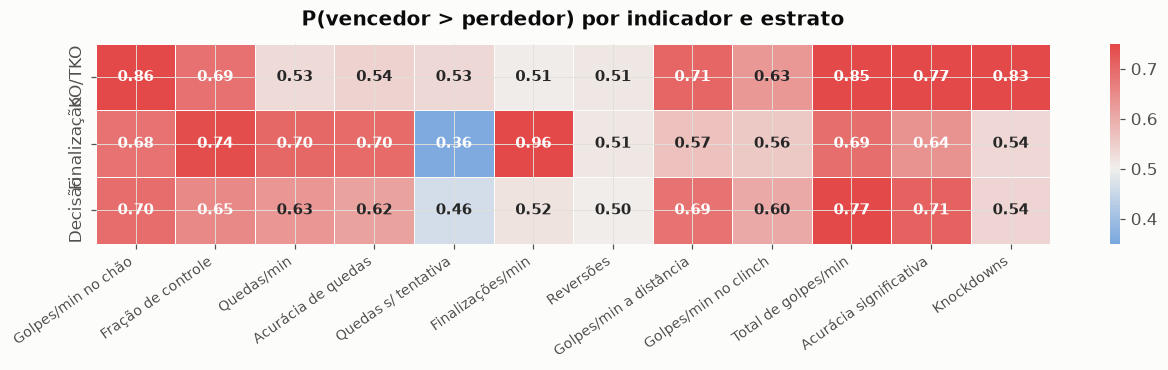

In [27]:
ps_data = {}
for estrato in ESTRATOS:
    sub = dataset[dataset.estrato == estrato]
    ps = {}
    for atrib in ATRIBUTOS:
        # dataset tem diferenças ref - oponente; y=1 -> ref ganhou
        # Diferença do ponto de vista do vencedor:
        vals = sub[atrib].values
        y = sub["y"].values
        signed = np.where(y == 1, vals, -vals)  # positivo = vencedor teve mais
        ps[atrib] = float(np.mean(signed > 0) + 0.5 * np.mean(signed == 0))
    ps_data[estrato] = ps

ps_df = pd.DataFrame(ps_data).T.reindex(columns=ATRIBUTOS)

fig, ax = plt.subplots(figsize=(12, 3.5))
sns.heatmap(
    ps_df,
    annot=True, fmt=".2f",
    cmap=DIVERGENTE, center=0.5, vmin=0.35, vmax=0.75,
    linewidths=0.4, linecolor=COR_FUNDO,
    ax=ax,
    xticklabels=[ROTULOS_ATRIB.get(a, a) for a in ATRIBUTOS],
    annot_kws={"size": 10, "weight": "bold"},
)
ax.set_title("P(vencedor > perdedor) por indicador e estrato", pad=12)
ax.set_ylabel("")
ax.set_xticklabels(ax.get_xticklabels(), rotation=35, ha="right", fontsize=9)
ax.set_facecolor(COR_FUNDO)
fig.patch.set_facecolor(COR_FUNDO)
fig.tight_layout()
salvar(fig, "fig10_prob_superioridade")
plt.show()


**Resultado.** A probabilidade de superioridade confirma as tendências do d, em uma escala que não depende da forma da distribuição. Os indicadores com maior valor em cada estrato são:

- **KO/TKO:** `ground_pm` (0,86), `total_pm` (0,85) e `kd` (0,83).
- **Finalização:** `sub_pm` (0,96) e `ctrl_share` (0,74).
- **Decisão:** `total_pm` (0,77), `sig_acc` (0,71), `ground_pm` (0,70) e `dist_pm` (0,69).

Nas decisões, `ground_pm` cai de 0,86 para 0,70 em relação a KO/TKO. Já `td_pm` sobe de 0,53 para 0,63.

**Leitura.** Em decisões, o total de golpes e a acurácia significativa separam vencedores e perdedores quase tão bem quanto em nocautes, o que mostra que as decisões não são definidas só pelo grappling. O grappling continua informativo, com P entre 0,62 e 0,70, mas perde força relativa no chão. Como em 6.5, os valores de 0,96 e 0,83 em `sub_pm` e `kd` refletem parcialmente a definição do estrato.

## 6.7 Ilustrando o viés de seleção

Lutas com grande domínio de grappling terminam antes — por KO/TKO ou finalização. Restringir a análise às decisões seleciona, portanto, lutas **mais equilibradas**. Esse fenômeno é chamado de **restrição de amplitude** (*range restriction*): ao observar apenas um subconjunto menos variável da população, correlações e tamanhos de efeito encolhem mesmo que a relação verdadeira não mude.

Dois ângulos ilustram esse viés:
1. **P(ir à decisão) × |Δctrl_share|**: lutas com diferenças extremas de controle raramente chegam às decisões — confirmando a seleção.
2. **Variância das diferenças por estrato**: a variância deve ser menor no estrato Decisão, pois as lutas muito desequilibradas foram filtradas.

Compreender esse viés é essencial para interpretar corretamente os resultados da Seção 7: uma redução do efeito de grappling em decisões pode refletir tanto uma mudança de tática quanto simplesmente a restrição de amplitude.


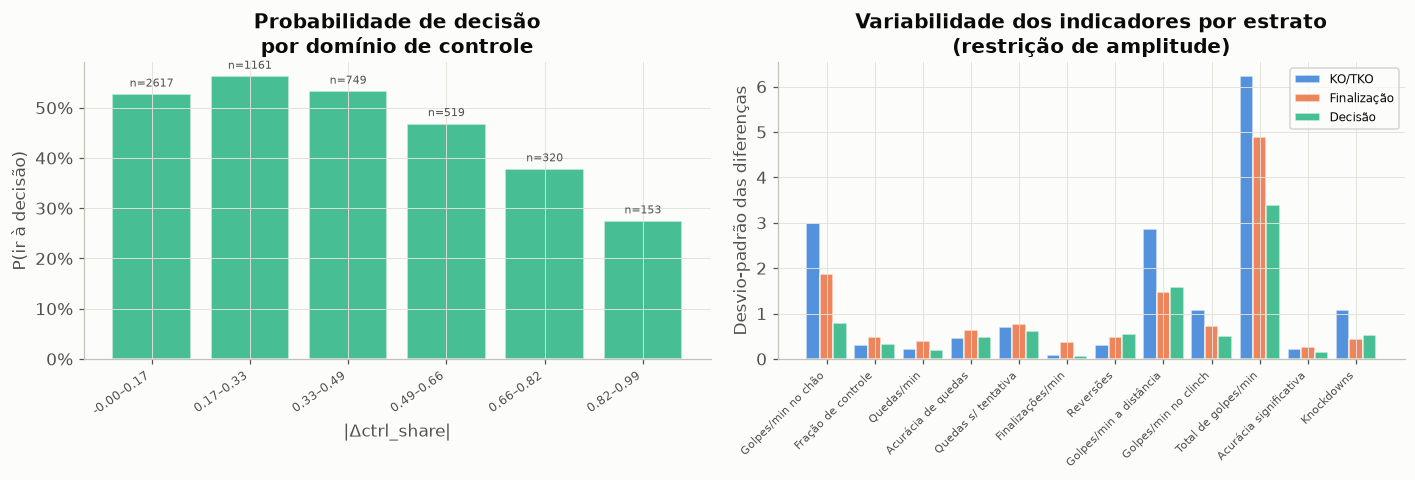

Desvio-padrão médio das diferenças por estrato:
estrato
KO/TKO         1.378
Finalização    1.068
Decisão        0.766


In [28]:
# Painel 1: P(decisão) por faixa de |Δctrl_share|
tmp = dataset.copy()
tmp["abs_ctrl"] = tmp["ctrl_share"].abs()
tmp["e_decisao"] = (tmp["estrato"] == "Decisão").astype(int)

n_bins = 6
tmp["faixa_ctrl"] = pd.cut(tmp["abs_ctrl"], bins=n_bins)
prob_dec = (
    tmp.groupby("faixa_ctrl", observed=False)["e_decisao"]
    .agg(["mean", "count"])
    .rename(columns={"mean": "P(decisão)", "count": "n"})
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

ax = axes[0]
midpoints = [iv.mid for iv in prob_dec.index]
ax.bar(
    range(len(prob_dec)), prob_dec["P(decisão)"],
    color=COR_ESTRATO["Decisão"], alpha=0.8, edgecolor=COR_FUNDO,
)
ax.set_xticks(range(len(prob_dec)))
ax.set_xticklabels(
    [f"{iv.left:.2f}–{iv.right:.2f}" for iv in prob_dec.index],
    rotation=35, ha="right", fontsize=8,
)
# Anotar n
for i, (_, row) in enumerate(prob_dec.iterrows()):
    ax.text(i, row["P(decisão)"] + 0.01, f"n={int(row.n)}",
            ha="center", va="bottom", fontsize=7, color=COR_TEXTO_2)
ax.set_xlabel("|Δctrl_share|")
ax.set_ylabel("P(ir à decisão)")
ax.set_title("Probabilidade de decisão\npor domínio de controle")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
ax.set_facecolor(COR_FUNDO)
ax.spines[["top", "right"]].set_visible(False)

# Painel 2: variância das diferenças por estrato
ax2 = axes[1]
var_estrato = (
    dataset.groupby("estrato", observed=True)[ATRIBUTOS]
    .std()
    .T
    .reindex(columns=ESTRATOS)
)

x = np.arange(len(ATRIBUTOS))
width = 0.28
for i, estrato in enumerate(ESTRATOS):
    ax2.bar(
        x + (i - 1) * width, var_estrato[estrato],
        width=width, label=estrato,
        color=COR_ESTRATO[estrato], alpha=0.8, edgecolor=COR_FUNDO,
    )
ax2.set_xticks(x)
ax2.set_xticklabels(
    [ROTULOS_ATRIB.get(a, a) for a in ATRIBUTOS],
    rotation=45, ha="right", fontsize=7,
)
ax2.set_ylabel("Desvio-padrão das diferenças")
ax2.set_title("Variabilidade dos indicadores por estrato\n(restrição de amplitude)")
ax2.legend(fontsize=8)
ax2.set_facecolor(COR_FUNDO)
ax2.spines[["top", "right"]].set_visible(False)

fig.patch.set_facecolor(COR_FUNDO)
fig.tight_layout()
salvar(fig, "fig11_vies_selecao")
plt.show()

print("Desvio-padrão médio das diferenças por estrato:")
print(var_estrato.mean().round(3).to_string())


**Resultado.** No painel da esquerda, a probabilidade de a luta chegar à decisão cai conforme aumenta a diferença de controle entre os lutadores. Para |Δctrl_share| até cerca de 0,5, ela fica entre 53% e 56%. Depois cai para cerca de 47%, 38% e, na faixa de 0,82 a 0,99, para cerca de 27% (n = 153). As seis faixas somam 5.519 lutas, a amostra analítica.

No painel da direita, o desvio-padrão médio das diferenças é de 1,38 em KO/TKO, 1,07 em Finalização e 0,77 em Decisão. A queda é mais forte em indicadores de volume, como golpes no chão e total de golpes. Em reversões, por outro lado, a dispersão é maior em Decisão.

**Leitura.** A seleção é clara para diferenças extremas de controle: lutas muito desequilibradas raramente chegam aos cartões. A restrição de amplitude, porém, não é uniforme. A média dos desvios-padrão mistura unidades diferentes e é dominada pelos indicadores de volume, então o valor 0,77 deve ser lido como indicação, e não como medida precisa. Para a Seção 7, isso significa que uma queda de d em Decisão pode vir tanto de uma mudança tática quanto da menor dispersão, o que justifica modelos com controle e não apenas a comparação de d.

## 6.8 Síntese da exploração

A análise exploratória revelou padrões consistentes que fundamentam e refinam a hipótese H3:

- **A composição dos estratos é estável no tempo** (6.1): a proporção de decisões oscila em torno de 50% de 2015 a 2025, sem tendência clara. Não há, portanto, indício de que as decisões estejam ganhando peso no UFC recente.

- **KO/TKO e finalizações são mais curtos** (6.2): a distribuição de duração é muito diferente entre estratos, confirmando que comparar indicadores por minuto sem controlar o estrato seria enganoso.

- **O grappling separa vencedores de perdedores nos três estratos, com intensidade variável** (6.3, 6.5, 6.6): `ground_pm` tem d de 0,92 em KO/TKO e de 0,65 em Decisão. `ctrl_share` e `td_pm` são relativamente mais informativos em Decisão (d de 0,72 e 0,56) do que em KO/TKO (0,41 e 0,15). Na probabilidade de superioridade, o total de golpes lidera em Decisão (0,77). O sinal favorece a H3 só em parte: o peso do chão cai, mas o do striking não sobe de forma clara.

- **`total_pm` é o indicador mais redundante, mas a redundância é moderada** (6.4): o VIF é 5,1, abaixo de 10, e sua correlação com `ground_pm` (0,71) reflete golpes compartilhados, não duplicação. Correlações de 0,7 entre pares como `ctrl_share` e `td_pm` não invalidam os modelos, mas tornam os coeficientes individuais menos precisos. Ainda assim, vale testar a remoção de `total_pm` nos modelos.

- **O viés de seleção é real e significativo** (6.7): a probabilidade de decisão cai de cerca de 55% para cerca de 27% conforme aumenta a diferença de controle. A dispersão dos indicadores de volume é menor em Decisão, mas isso não vale para todos: em reversões, ela é maior nas decisões. Parte da diferença entre estratos pode, portanto, ser restrição de amplitude, e não só mudança tática. Este é o alerta metodológico central para as seções seguintes.


# 7. Que tipo de problema é este?

- **Classificação binária supervisionada**: y = 1 se o lutador de referência venceu.
- **Classes balanceadas por construção** (sorteio da referência), então acurácia e AUC são comparáveis entre estratos.
- **Explicativo, não preditivo.** As estatísticas são medidas *durante* a luta; o modelo descreve o que separa vencedores de perdedores, não prevê lutas futuras. Prever lutas exigiria estatísticas anteriores de cada lutador, outro desenho.
- O teste da hipótese é **inferencial** (Seção 8); os modelos de aprendizado de máquina (Seções 9–12) confirmam o resultado sem supor linearidade.

# 8. Teste formal da hipótese

Comparar dois modelos "no olho" não é um teste estatístico. O teste de H3a é a significância dos **termos de interação** estrato × indicador em uma única regressão logística:

$$
\operatorname{logit} P(y=1) = \sum_k \beta_k\, \Delta x_k + \sum_{s \neq \text{Decisão}} \sum_k \gamma_{sk}\, \Delta x_k \cdot \mathbb{1}[\text{estrato}=s]
$$

- **Decisão** é a categoria de referência: $\beta_k$ é o efeito do indicador $k$ nas decisões e $\gamma_{sk}$ é quanto ele muda no estrato $s$.
- H3a prevê $\gamma_{sk} > 0$ para os indicadores de grappling.
- As diferenças são padronizadas **na amostra inteira** (não dentro de cada estrato), para que os coeficientes fiquem na mesma escala e a restrição de amplitude da Seção 6.7 não seja confundida com mudança de efeito.
- **Erros-padrão agrupados** pelos dois lutadores da luta (agrupamento bidirecional), porque o mesmo atleta aparece em várias lutas.

Testes:
1. **Wald conjunto** do bloco de interações de grappling (H3a);
2. **Wald** de $\beta_{\text{ctrl\_share}} = \beta_{\text{ground\_pm}}$ dentro das decisões (H3b);
3. comparação dos coeficientes de striking à distância entre o modelo agregado e o estrato de decisões (H3c).

`<Atenção a separação quase perfeita no estrato KO/TKO (kd, ground_pm); se ocorrer, usar regularização leve ou reportar.>`

In [45]:
# H3a: logística com interações estrato × indicador. Decisão é a referência.
# Sem intercepto por simetria: trocar ref ↔ oponente inverte Δ e y, logo a logit é ímpar em Δ.
# Δ é padronizado pelo desvio-padrão da amostra inteira (não por estrato), para que os coeficientes
# fiquem na mesma escala e a restrição de amplitude (6.7) não seja confundida com mudança de efeito.
DP_GERAL = dataset[ATRIBUTOS].std(ddof=0)
Z = dataset[ATRIBUTOS].div(DP_GERAL).to_numpy()
K = len(ATRIBUTOS)
ESTRATOS_INTERACAO = ["KO/TKO", "Finalização"]

blocos = [Z]
for s in ESTRATOS_INTERACAO:
    ind = (dataset["estrato"] == s).to_numpy(dtype=float)[:, None]
    blocos.append(Z * ind)
X = np.hstack(blocos)  # colunas: β (12 da Decisão), γ KO/TKO (12), γ Finalização (12)

def pos(estrato, atrib):
    """Posição do coeficiente: β na Decisão; γ nos demais estratos."""
    j = ATRIBUTOS.index(atrib)
    if estrato == "Decisão":
        return j
    return K * (1 + ESTRATOS_INTERACAO.index(estrato)) + j

# Erros-padrão agrupados pelos dois lutadores (cluster bidirecional: referência e oponente).
codigos = pd.factorize(pd.concat([dataset["ref_id"], dataset["opp_id"]], ignore_index=True))[0]
n = len(dataset)
grupos = np.column_stack([codigos[:n], codigos[n:]])

modelo = sm.Logit(dataset["y"].to_numpy(), X)
res = modelo.fit(cov_type="cluster", cov_kwds={"groups": grupos}, disp=0, maxiter=500)
V = res.cov_params()

print("Convergiu:", res.mle_retvals.get("converged"), "| maior coef:", round(float(np.abs(res.params).max()), 2))
if not res.mle_retvals.get("converged", True) or np.abs(res.params).max() > 10:
    warnings.warn("Possível separação quase perfeita (ver a nota da seção 8). Considere regularização leve ou reporte.")

Convergiu: True | maior coef: 2.63


H3a, Wald conjunto (14 γ de grappling = 0): χ²(14) = 157.09, p = 2.724e-26
H3a, KO/TKO: χ²(7) = 88.02, p = 3.16e-16
H3a, Finalização: χ²(7) = 65.46, p = 1.215e-11
H3b: β_ctrl − β_ground (Decisão) = -1.585 (EP 0.381), IC95% [-2.330; -0.839]
     Wald bilateral de igualdade: p = 3.129e-05; unilateral (> 0): p = 1


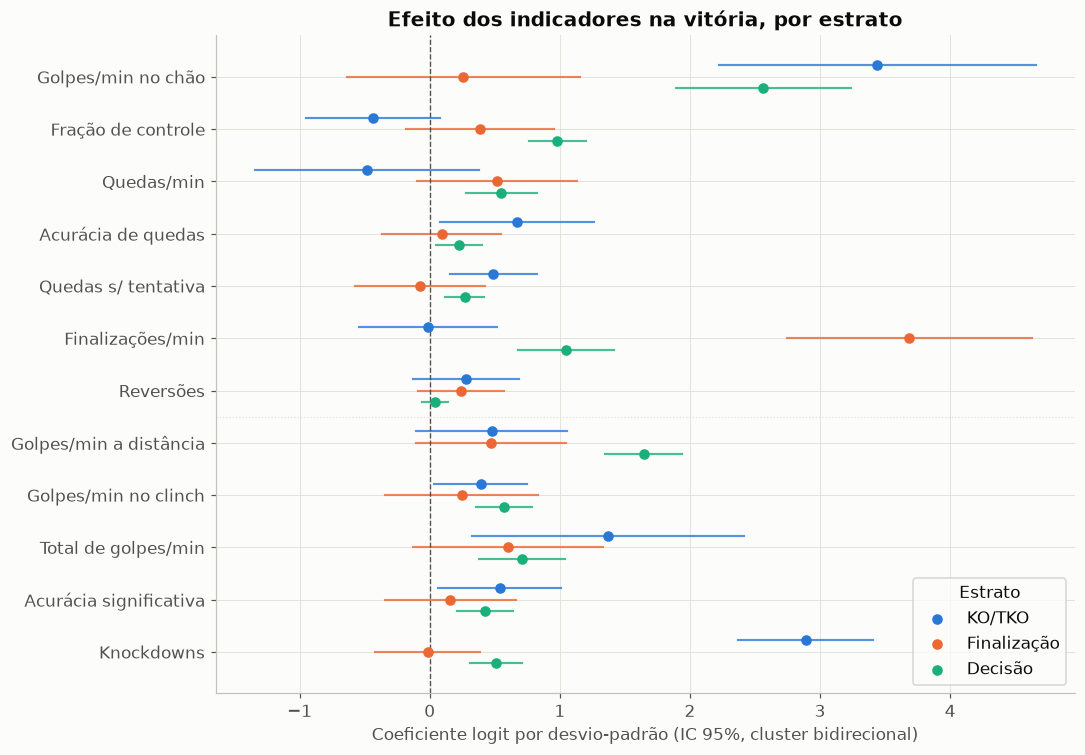

In [46]:
# H3a: H0 é γ = 0 para os 7 indicadores de grappling nos dois estratos; H3a prevê γ > 0.
G_todos = [pos(s, k) for s in ESTRATOS_INTERACAO for k in GRAPPLING]
R_h3a = np.zeros((len(G_todos), X.shape[1]))
R_h3a[np.arange(len(G_todos)), G_todos] = 1
wald_h3a = res.wald_test(R_h3a)
print(f"H3a, Wald conjunto (14 γ de grappling = 0): χ²({len(G_todos)}) = "
      f"{float(np.squeeze(wald_h3a.statistic)):.2f}, p = {float(np.squeeze(wald_h3a.pvalue)):.4g}")

for s in ESTRATOS_INTERACAO:
    G_s = [pos(s, k) for k in GRAPPLING]
    R_s = np.zeros((len(G_s), X.shape[1]))
    R_s[np.arange(len(G_s)), G_s] = 1
    w = res.wald_test(R_s)
    print(f"H3a, {s}: χ²({len(G_s)}) = {float(np.squeeze(w.statistic)):.2f}, p = {float(np.squeeze(w.pvalue)):.4g}")

tab_h3a = []
for s in ESTRATOS_INTERACAO:
    for k in GRAPPLING:
        j = pos(s, k)
        g, ep = res.params[j], np.sqrt(V[j, j])
        tab_h3a.append({
            "estrato": s, "indicador": k, "γ": g, "EP": ep,
            "IC95 inf": g - 1.96 * ep, "IC95 sup": g + 1.96 * ep,
            "p unilateral (γ > 0)": 1 - stats.norm.cdf(g / ep),
        })
tab_h3a = pd.DataFrame(tab_h3a).round(4)
tab_h3a

# H3b: nas decisões, o controle é o indicador de grappling mais ligado à vitória, à frente do chão.
# Teste: β_ctrl_share − β_ground_pm > 0, com teste bilateral de igualdade como referência.
j_ctrl, j_ground = pos("Decisão", "ctrl_share"), pos("Decisão", "ground_pm")
R_h3b = np.zeros((1, X.shape[1]))
R_h3b[0, j_ctrl], R_h3b[0, j_ground] = 1, -1
wald_h3b = res.wald_test(R_h3b)
dif = float(R_h3b[0] @ res.params)
ep_dif = float(np.sqrt(R_h3b[0] @ V @ R_h3b[0]))
z_h3b = dif / ep_dif
print(f"H3b: β_ctrl − β_ground (Decisão) = {dif:.3f} (EP {ep_dif:.3f}), "
      f"IC95% [{dif - 1.96 * ep_dif:.3f}; {dif + 1.96 * ep_dif:.3f}]")
print(f"     Wald bilateral de igualdade: p = {float(np.squeeze(wald_h3b.pvalue)):.4g}; "
      f"unilateral (> 0): p = {1 - stats.norm.cdf(z_h3b):.4g}")

# Ranking dos indicadores de grappling dentro das decisões
rank_h3b = pd.DataFrame([{
    "indicador": k, "β (Decisão)": res.params[pos("Decisão", k)],
    "EP": np.sqrt(V[pos("Decisão", k), pos("Decisão", k)]),
} for k in GRAPPLING]).sort_values("β (Decisão)", ascending=False).round(4)
rank_h3b

# Efeito de cada indicador em cada estrato: β (Decisão), β + γ (KO/TKO e Finalização), IC 95% cluster bidirecional.
def efeito(estrato, k):
    v = np.zeros(X.shape[1])
    v[pos("Decisão", k)] += 1.0
    if estrato != "Decisão":
        v[pos(estrato, k)] += 1.0
    return float(v @ res.params), float(np.sqrt(v @ V @ v))

tab_efeitos = pd.DataFrame([
    {"estrato": s, "atributo": k, "coef": efeito(s, k)[0], "ep": efeito(s, k)[1]}
    for s in ESTRATOS for k in ATRIBUTOS
])

ORDEM = GRAPPLING + STRIKING
fig, ax = plt.subplots(figsize=(10, 7))
offsets = {est: o for est, o in zip(ESTRATOS, [-0.22, 0, 0.22])}
for s in ESTRATOS:
    sub = tab_efeitos[tab_efeitos.estrato == s]
    for i, k in enumerate(ORDEM):
        r = sub[sub.atributo == k].iloc[0]
        y_pos = i + offsets[s]
        ax.plot([r.coef - 1.96 * r.ep, r.coef + 1.96 * r.ep], [y_pos, y_pos],
                color=COR_ESTRATO[s], linewidth=1.4, alpha=0.8)
        ax.scatter(r.coef, y_pos, color=COR_ESTRATO[s], s=35, zorder=5,
                   label=s if i == 0 else "")
ax.axvline(0, color=COR_TEXTO_2, linewidth=0.9, linestyle="--")
ax.axhline(len(GRAPPLING) - 0.5, color=COR_GRADE, linewidth=0.8, linestyle=":")
ax.set_yticks(range(len(ORDEM)))
ax.set_yticklabels([ROTULOS_ATRIB.get(k, k) for k in ORDEM])
ax.invert_yaxis()
ax.set_xlabel("Coeficiente logit por desvio-padrão (IC 95%, cluster bidirecional)")
ax.set_title("Efeito dos indicadores na vitória, por estrato")
ax.legend(title="Estrato", loc="lower right")
ax.set_facecolor(COR_FUNDO)
fig.patch.set_facecolor(COR_FUNDO)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
salvar(fig, "fig12_h3_coeficientes_estrato")
plt.show()

### Interpretação

**H3a: não confirmada na forma prevista.** O teste conjunto rejeita a igualdade dos efeitos entre estratos: χ²(14) = 157,1, p < 0,001 (KO/TKO: χ²(7) = 88,0; Finalização: χ²(7) = 65,5). Mas esse teste é bilateral. A previsão é γ > 0 para todos os indicadores de grappling, e os sinais não seguem esse padrão. Os valores abaixo são lidos do gráfico (coeficientes por desvio-padrão, na escala logit):

- **Chão (`ground_pm`):** em KO/TKO o efeito é maior que nas decisões (≈ 3,4 contra ≈ 2,6), o que vai ao encontro da H3a. Nas finalizações, o efeito é bem menor (≈ 0,25).
- **Controle (`ctrl_share`):** o efeito é menor nos dois outros estratos (≈ −1,4 em KO/TKO e ≈ −0,6 em Finalização, em relação às decisões). O controle pesa mais justamente nas decisões, o oposto da previsão.
- **Quedas (`td_pm`):** menor em KO/TKO (≈ −0,95) e praticamente igual nas finalizações. Também contraria a previsão.
- **Finalizações/min (`sub_pm`):** γ ≈ +2,7 em Finalização. Esse indicador é parte da definição do estrato, então o valor não é evidência a favor da H3a.
- **Quedas com acurácia, quedas sem tentativa e reversões:** diferenças pequenas e com sinais variados.

Em resumo, os efeitos mudam entre estratos, mas não de forma uniforme. O grappling não perde força nas decisões como um bloco: o chão perde, e o controle e as quedas ganham. Por isso a H3a não se sustenta como previsão geral.

**H3b: refutada.** Nas decisões, β_ctrl_share − β_ground_pm = −1,59 (EP = 0,38; IC 95%: −2,33 a −0,84). O teste unilateral de que o controle supera o chão dá p = 1, ou seja, a diferença está no sentido contrário. Nas decisões, o golpe no chão é o indicador de grappling mais associado à vitória (≈ 2,6 por DP), e o controle fica perto de 1,0.

Ressalvas que afetam a leitura:

1. **Escala e caudas pesadas:** `ground_pm` tem mediana de 0,07 por minuto e máximo de 22,8, com DP de 1,3. A maioria das lutas está muito abaixo de 1 DP, então o coeficiente por DP depende muito de valores extremos. Vale refazer com transformação por quantis (`QuantileTransformer`, já importado) para verificar se o resultado se mantém.
2. **Indicadores definidos pelo desfecho:** `sub_pm` infla o teste conjunto de H3a. É recomendado refazê-lo sem essa variável.
3. **Correlações:** `ctrl_share` e `td_pm` têm r = 0,70, o que aumenta o erro-padrão de cada um. A comparação de H3b envolve `ctrl_share` e `ground_pm` (r = 0,43), menos afetados por isso, mas os efeitos condicionais dependem dos demais controles.
4. **Valores exatos:** a tabela `tab_h3a` (γ, EP, IC e p unilateral por indicador) não é exibida na célula de testes. Os números acima vêm do gráfico. Para os valores exatos, basta exibir `tab_h3a`.
5. **Sem separação:** o modelo convergiu, e o maior coeficiente em módulo é 2,63, abaixo do limiar de alerta de 10.

`<H3c>`

# 9. Modelos supervisionados: ajuste e seleção

## 9.1 Divisão treino/teste

Divisão **estratificada por estrato × y**, 75% treino / 25% teste, antes de qualquer decisão de modelagem. O teste é usado uma única vez, na Seção 12.

## 9.2 Pipeline e modelos

Toda transformação dependente dos dados (padronização, seleção, PCA) fica **dentro do `Pipeline`**, ajustada só no treino de cada dobra.

| Modelo | Por quê | Hiperparâmetros (busca) |
|---|---|---|
| Regressão logística L2 / L1 / Elastic Net | Linha de base interpretável; L1 também seleciona atributos | `C`, `l1_ratio` (grade) |
| Árvore de decisão (CART) | Análoga ao CHAID de James et al.; regras legíveis | `max_depth`, `min_samples_leaf` ≥ 10 (grade) |
| Floresta aleatória | Não linearidades e interações | `n_estimators`, `max_depth`, `max_features` (aleatória) |
| Gradient boosting (`HistGradientBoosting`) | Referência forte em dados tabulares | `learning_rate`, `max_depth`, `l2_regularization` (aleatória) |

Validação cruzada **5-fold estratificada** no treino para escolher hiperparâmetros. Ajustes feitos **por estrato** e no **conjunto agregado** (que reproduz o desenho de James et al.).

In [31]:
# TODO: train_test_split estratificado por estrato × y.

In [32]:
# TODO: pipelines e grades; GridSearchCV / RandomizedSearchCV por estrato e no agregado.

# 10. Comparação dos modelos

## 10.1 Métricas

Mesmo protocolo para todos (CV repetida 5 × 5 no treino):

- **ROC-AUC** (métrica principal; usa probabilidades);
- acurácia e F1 (classes balanceadas);
- **Brier score** e **log-loss** (qualidade das probabilidades);
- curva de calibração.

`<Tabela modelos × estratos × métricas; boxplot das AUCs das dobras.>`

In [33]:
# TODO: tabela comparativa e boxplot das AUCs por modelo e estrato.

## 10.2 Quanto o grappling acrescenta? ΔAUC por bloco (figura principal 2)

Para cada estrato, comparamos três conjuntos de atributos com o mesmo modelo e protocolo:

1. só striking; 2. só grappling; 3. completo.

O **ΔAUC = AUC(completo) − AUC(só striking)** mede a informação que o grappling acrescenta. Se H3 for verdadeira, o ΔAUC é menor no estrato de decisões. Intervalos pelas repetições da CV.

`<Gráfico de pontos com IC: ΔAUC do bloco de grappling por estrato.>`

In [34]:
# TODO: AUC por bloco de atributos e estrato; gráfico do ΔAUC.

### Interpretação

`<O melhor modelo depende do estrato? A conclusão muda com a métrica? O ΔAUC do grappling cai nas decisões?>`

# 11. É possível melhorar? Projeção, seleção e transformação

Testes no estrato focal (Decisão), sempre dentro do pipeline:

| Estratégia | Ideia |
|---|---|
| **Projeção** (PCA) | Reduzir a redundância entre contagens de golpes; quantos componentes explicam 90% da variância? Gráfico 2D colorido por y |
| **Seleção** (L1, RFECV, importância por permutação) | Menos atributos com a mesma AUC? Quais sobrevivem? |
| **Transformação** (`log1p`, `QuantileTransformer`) | Atenuar assimetria e outliers das taxas por minuto |
| **Validação temporal** | Treinar em 2015–2022 e testar em 2023–2026: as relações são estáveis no tempo? |

`<Tabela: AUC na CV de cada variante contra a linha de base.>`

In [35]:
# TODO: PCA (variância explicada + projeção 2D).

In [36]:
# TODO: seleção de atributos e transformações; comparação de AUC na CV.

In [37]:
# TODO: validação temporal (treino até 2022, teste 2023+).

# 12. Resultados finais e importância das variáveis

## 12.1 Avaliação no conjunto de teste

`<Modelo final de cada estrato avaliado uma única vez no teste: AUC, acurácia, F1, Brier, curva ROC e matriz de confusão.>`

In [38]:
# TODO: avaliação final no teste por estrato.

## 12.2 Importância das variáveis por estrato

`<Importância por permutação no teste (indicadores × estratos, mapa de calor) e coeficientes padronizados da logística. Testa H3b (ctrl_share > ground_pm nas decisões) e H3c (dist_pm ganha peso nas decisões).>`

In [39]:
# TODO: importância por permutação e coeficientes por estrato.

## 12.3 As árvores mudam de estrutura?

`<Árvores rasas (profundidade 3, min_samples_leaf ≥ 10) por estrato, lado a lado. Comparar com as regras de James et al. (> 0,850 golpes no solo/min; precisão de quedas > 25%).>`

In [40]:
# TODO: árvores por estrato e comparação com os limiares de James et al.

# 13. Análises de sensibilidade

O resultado principal se mantém quando mudamos o recorte?

| Variante | Motivo |
|---|---|
| Só lutas de 3 rounds | Lutas de 5 rounds são poucas e diferentes (eventos principais) |
| Sem lutas de título | Perfil de atleta distinto |
| 2015–2016 × 2017+ | Revisão dos critérios de julgamento em 2017 |
| Só masculino / só feminino | Perfil de striking diferente nas divisões femininas |
| Janela ampliada (2000+) | Mais lutas; o sorteio da referência resolve o problema da ordem A/B |
| Duração mínima de 30 s ou 120 s | O limiar de 60 s da Seção 3.6 é uma escolha |
| Outra semente do sorteio | O resultado não depende do sorteio |

`<Gráfico de pontos: a estatística principal (ΔAUC do grappling ou coeficiente de interação) em cada variante.>`

In [41]:
# TODO: repetir a análise principal em cada variante.

# 14. Análise exploratória secundária: o placar dos juízes

Análise **exploratória**, sem reivindicar novidade (o tema é coberto por Latshaw e Gift). Dentro do estrato de decisões, a margem do placar (`judges_scores`) mede *por quanto* o vencedor ganhou.

`<Margem total do placar e tipo de decisão (unânime × dividida) em função das diferenças de ctrl_share e dist_pm do vencedor. Correlação de Spearman.>`

In [42]:
# TODO: margem dos juízes × diferenças de controle e de striking.

# 15. Discussão

## 15.1 Principais resultados

`<Resposta direta à hipótese: o efeito do grappling se dissolve, encolhe ou persiste nas decisões? Com números (coeficientes, ΔAUC, d).>`

## 15.2 Interpretação da bifurcação

`<Se encolhe: o achado de James et al. estava inflado pela mecânica da finalização. Se persiste: é evidência sobre o que os juízes premiam, não sobre o que vence lutas. Relação com Miarka et al. e James et al. (2019).>`

## 15.3 Limitações

- **Viés de seleção:** condicionar na decisão é condicionar em um evento pós-tratamento; os resultados são condicionais, não causais.
- **Restrição de amplitude:** parte da redução de efeito pode vir só da menor variância nas decisões (Seção 6.7).
- **Definição de tempo de controle:** o UFC Stats não publica glossário; não está claro se inclui controle no clinch contra a grade.
- **Sem *offensive passes*:** um dos indicadores de James et al. não existe no UFC Stats.
- **Dados observacionais, só UFC:** generalização restrita.
- **Explicativo, não preditivo:** as estatísticas são da própria luta.

## 15.4 Como melhorar

`<Ex.: estatísticas pré-luta para predição real; análise round a round (round_stats) com scorecards por round; modelos mistos com efeito aleatório por lutador; validar a definição de controle com vídeo.>`

# 16. Conclusão e sumário do projeto

| Etapa | O que foi feito | Resultado |
|---|---|---|
| Pergunta | O grappling ainda separa vencedores quando ninguém finaliza? | |
| Dados | UFC Stats, coleta 2026-09-21, 2015+ | `<n lutas por estrato>` |
| Preparação | Exclusões, duração mínima, sorteio da referência | |
| Exploração | Cohen's *d* e probabilidade de superioridade por estrato | |
| Inferência | Logística com interação, SE agrupado | `<H3a, H3b, H3c>` |
| Modelos | Logística, árvore, floresta, boosting | `<melhor modelo e AUC por estrato>` |
| Melhorias | PCA, seleção, transformação, validação temporal | |
| Sensibilidade | 7 variantes | |
| Conclusão | | `<hipótese confirmada / refutada>` |

`<Parágrafo final de conclusão.>`

## Referências

- James, L. P., Robertson, S., Haff, G. G., Beckman, E. M., & Kelly, V. G. (2016). Identifying the performance characteristics of a winning outcome in elite mixed martial arts competition. *Journal of Science and Medicine in Sport*.
- James, L. P. et al. (2019). `<título>`. *Frontiers in Artificial Intelligence*. (2.831 lutas, 2000–2015, nMDS e RIPPER.)
- Miarka, B. et al. (2016). `<título>`. *Journal of Strength and Conditioning Research*, 30(7), 1975–1984.
- Miarka, B. et al. (2018). `<título>`. *Journal of Strength and Conditioning Research*, 32(2), 534–544.
- Gift, P. (2021). `<título>`. *Journal of Sports Analytics*.
- Latshaw, N. JudgeAI. `<link>`.
- Dados: UFC Stats (http://ufcstats.com), via `ufc-stats-scraper` (https://github.com/JuanHPassos/ufc-stats-scraper), coleta de 2026-09-21.

`<Conferir e completar as referências (títulos, volumes, DOIs) antes da entrega.>`